# TritFlow: balanced-ternary HDL to GDS on OpenSUSI TR-1um

TritFlow turns balanced-ternary HDL into checked GDS and extracted SPICE
waveforms on Japan's [OpenSUSI TR-1um](https://github.com/OpenSUSI/TR-1um).
Its library adapts the [author's taped-out ternary cells](https://github.com/PenguinEino/opensusi-tr10-balanced-ternary-logic).
**Choose Runtime → Run all** to follow an adder from its middle-voltage
divider to layout, then edit your own circuit.

The reference cells were taped out in 2026; silicon is
expected in January 2027 and has not yet been measured.



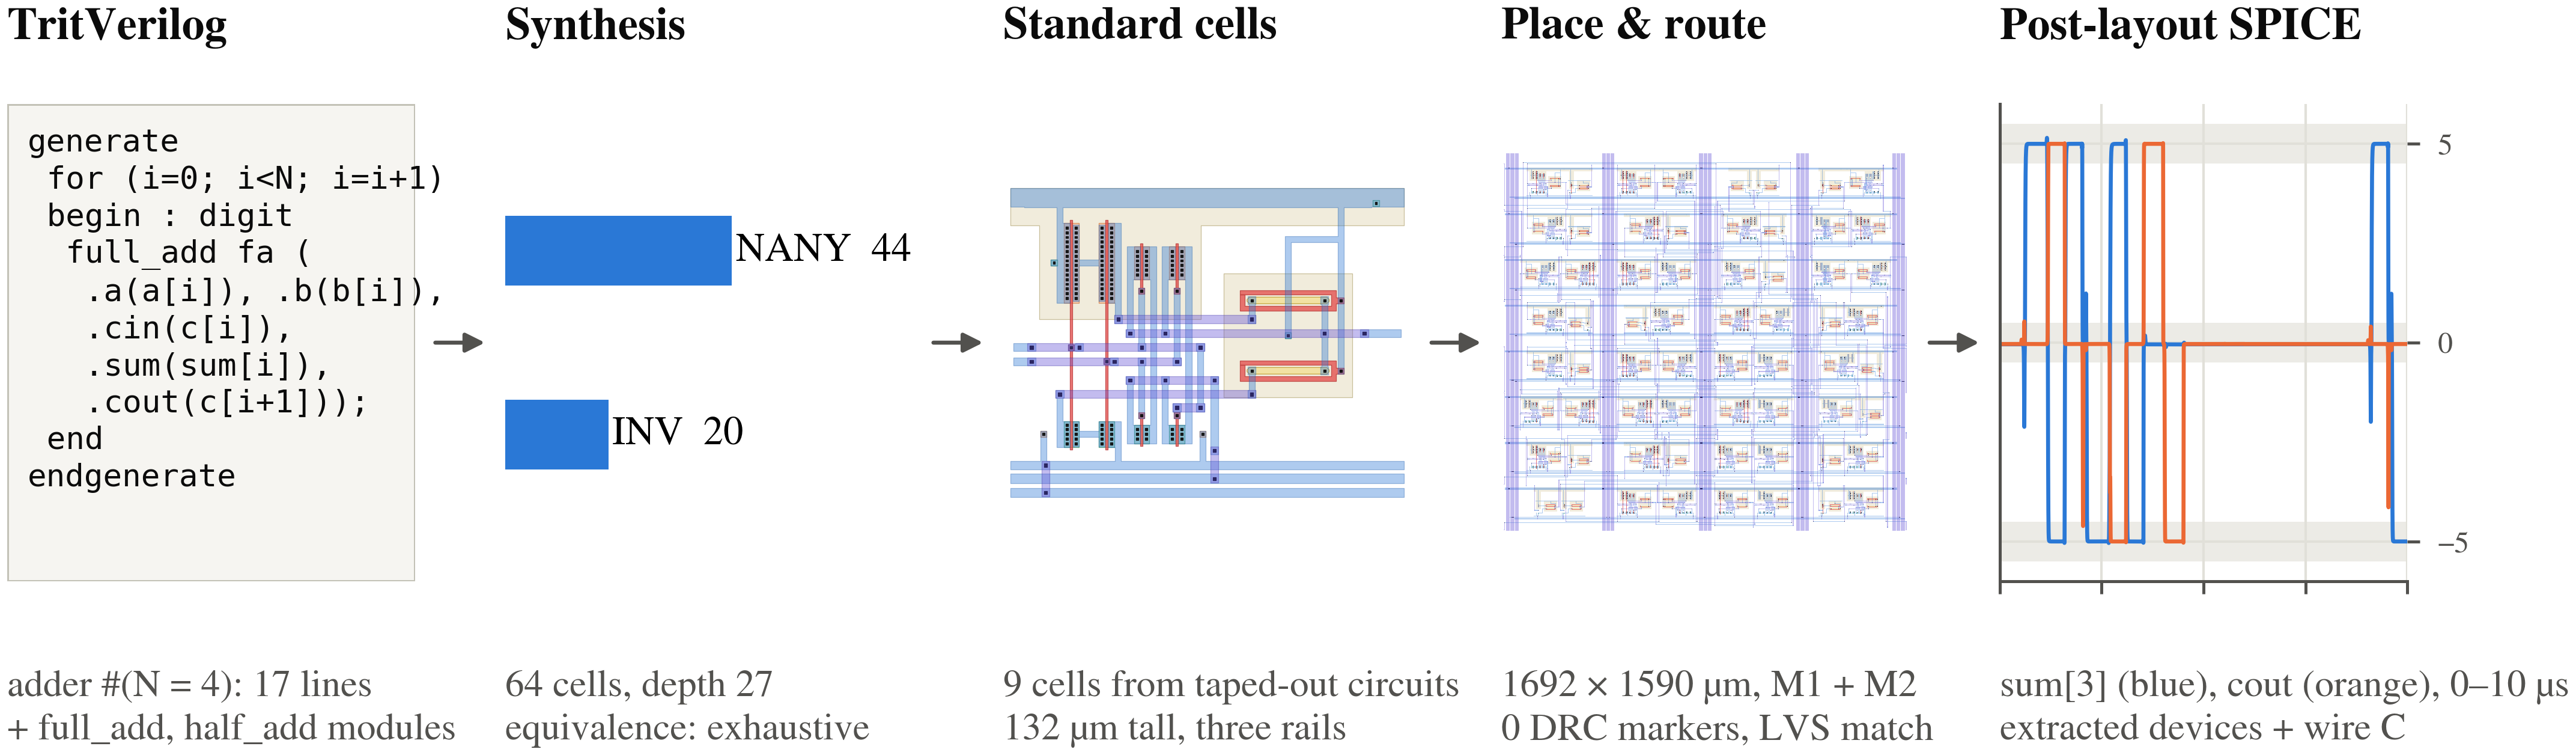

**The illustrated 4-trit adder:** 17 top-level HDL lines plus shared modules → 64 cells, a 1692 × 1590 µm GDS, 0 drawing-DRC markers and LVS Match.

The middle level has a standing cost: 4.17 mW per mapped cell for this adder mix, reaching 0.4 W at 6 trits. Sizing trades current against voltage accuracy.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PenguinEino/tritflow/blob/colab-v0/notebook/tritflow_tr1um.ipynb)

Free Colab verification at [7b62e63](https://github.com/PenguinEino/tritflow/commit/7b62e63f9f75acfa5f935c8da58a77a9db42e0cc): all 35 code cells completed in 384.4 s including setup.

If Run all stops after setup, choose Run all again.

<details><summary>Author and license</summary>

- Name: Einosuke Okazaki (岡崎 英之介)
- Affiliation: Information and Communication Engineering Course, Department of Monozukuri
  Engineering, Tokyo Metropolitan College of Industrial Technology (KOSEN), Tokyo, Japan
- Status: Fifth-year student (final year of the five-year KOSEN engineering programme, which
  combines upper-secondary and the first two years of tertiary education)
- Email: einosukeokazaki@gmail.com
- GitHub: PenguinEino

Einosuke Okazaki will attend ISSCC 2027 in person and present the poster if selected (confirmed by the author, 2026-10-18).

Apache-2.0, including historical schematic assets released by their author.

</details>


In [ ]:
#@title Setup: clone TritFlow at the release tag, install KLayout and ngspice, fetch the pinned TR-1um PDK { display-mode: "form" }
_TRITFLOW_SETUP_READY = False
globals().pop("_tf_cells", None)
import os, sys, json, time, hashlib, subprocess, importlib.util
from pathlib import Path
started = time.monotonic()
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
SOURCE_URL = "https://github.com/PenguinEino/tritflow.git"
SOURCE_REF = os.environ.get("TRITFLOW_REF", "colab-v0")
def source_git(*args):
    return subprocess.check_output(["git", "-C", str(ROOT), *args], text=True).strip()
if IN_COLAB:
    ROOT = Path("/content/tritflow")
    if not SOURCE_REF or SOURCE_REF.startswith("-") or any(c.isspace() for c in SOURCE_REF):
        raise ValueError("TRITFLOW_REF must name a Git tag or branch")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--single-branch", "--branch", SOURCE_REF,
                        SOURCE_URL, str(ROOT)], check=True)
    if not (ROOT/".git").is_dir():
        raise RuntimeError("/content/tritflow must be a git clone; use a fresh Colab runtime")
    if source_git("remote", "get-url", "origin").removesuffix(".git") != SOURCE_URL.removesuffix(".git"):
        raise RuntimeError("existing checkout has a different origin; use a fresh Colab runtime")
    SOURCE_COMMIT = source_git("rev-parse", "--verify", "HEAD^{commit}")
    requested_commit = source_git("rev-parse", "--verify", SOURCE_REF+"^{commit}")
    if SOURCE_COMMIT != requested_commit or source_git("status", "--porcelain", "--untracked-files=no"):
        raise RuntimeError("existing checkout differs from TRITFLOW_REF; use a fresh Colab runtime")
    print(f"Source: {SOURCE_URL} ref={SOURCE_REF} commit={SOURCE_COMMIT}", flush=True)
    if not (ROOT/"notebook/runtime_support.py").is_file():
        raise RuntimeError("TRITFLOW_REF predates this notebook's setup. Select its matching immutable release with TRITFLOW_REF in a fresh runtime.")
    sys.path.insert(0, str(ROOT/"notebook"))
    from runtime_support import SETUP_SCHEMA
    runtime = ROOT/"notebook/runtime.json"
    if not runtime.is_file() or json.loads(runtime.read_text()).get("TRITFLOW_SETUP_SCHEMA") != SETUP_SCHEMA:
        subprocess.run(["bash", str(ROOT/"notebook/colab_setup.sh"), "--source", str(ROOT)], check=True)
    os.environ.update(json.loads(runtime.read_text()))
else:
    candidates = [Path(os.environ.get("TRITFLOW_ROOT", ".")), Path.cwd(), Path.cwd().parent]
    ROOT = next((p.resolve() for p in candidates if (p/"pyproject.toml").is_file()
                 and (p/"tritflow").is_dir()), None)
    if ROOT is None:
        raise RuntimeError("run locally from the full checkout or set TRITFLOW_ROOT")
    SOURCE_COMMIT = source_git("rev-parse", "--verify", "HEAD^{commit}") if (ROOT/".git").exists() else "tracked-tree export (no .git)"
    print(f"Source: {ROOT} commit={SOURCE_COMMIT}")
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT/"notebook"))
os.environ.setdefault("QT_QPA_PLATFORM", "offscreen")
from runtime_support import check_runtime, print_tool_versions
check_runtime()
print_tool_versions()
_TRITFLOW_SETUP_READY = True


In [ ]:
#@title Imports and run bookkeeping { display-mode: "form" }
NARRATIVE_CONTEXT_SHA256 = 'a7807b8d0730a28f66d3bc357934aba9ce619ffa1bb10ba3022f760fea6402fd'

globals().pop("_tf_cells", None)
if not globals().get("_TRITFLOW_SETUP_READY", False):
    raise RuntimeError("Run the first setup cell successfully, then rerun the imports cell. If setup requested a restart, restart once first.")
from runtime_support import CellState
import numpy as np
from IPython.display import display, HTML, Image
from tritflow import flow, CELLS_DIR, PDK_ROOT, PASS_BAND, TRIT_VOLTS
from tritflow.sim import dc_transfer, input_vectors, subcircuits
from tritflow.viz.graph import truth_table_html
from tritflow.viz.waves import waveform_figure
from tritflow.viz.layout import render_gds, placement_animation, routing_progress
from tritflow.viz.cell import device_mapping
from tritflow.sim.provenance import pdk_provenance
from tritflow.sim.postlayout import logical_nodeset
from cache import Cache, runtime_fingerprint, source_manifest
from campaign import RecordedCampaign
from schematics import schematic_gallery
from experiments import (complete_design, experiment_artifacts, assert_experiment,
                         load_edited, verify_publication_sources, adder_demo_vectors)
EXTENDED = os.environ.get("TRITFLOW_EXTENDED", "0") == "1"
BUILD = Path(os.environ.get("TRITFLOW_NOTEBOOK_BUILD", ROOT/"build/notebook")).resolve()
qualified_pdk = pdk_provenance(PDK_ROOT)
assert qualified_pdk["qualified_commit"] == json.loads((ROOT/"notebook/setup_pins.json").read_text())["pdk_commit"]
native_sources = source_manifest(ROOT,PDK_ROOT)
cache = Cache(BUILD/"cache", runtime_fingerprint(ROOT, PDK_ROOT,names=native_sources),
              force=os.environ.get("TRITFLOW_FORCE_RUN", "0") == "1",sources=native_sources)
recorded_campaign = RecordedCampaign(ROOT/"notebook/assets/four_designs.zip",ROOT,PDK_ROOT,
                                     enabled=not cache.force)
renderer_sha256 = hashlib.sha256((ROOT/"tritflow/viz/layout.py").read_bytes()).hexdigest()
from presentation import show, table, evidence

from IPython.display import Markdown, Code
from editorial import context, context_identity, render as render_narrative, dimensions
from paper_evidence import load_paper
from learning import sizing_slider, value_selector, highlight_devices
from predictions import divider, zero_dc, rail_power
from presentation import details_html, details_svg
from routing_identity import routing_label, archive_routing
paper = load_paper(ROOT)
narrative_values = context(ROOT)
assert context_identity(narrative_values) == NARRATIVE_CONTEXT_SHA256, "Published figure measurements changed; regenerate the notebook before running."

_tf_cells = CellState({'setup': 'setup', 'imports': 'imports', 'opening_inputs': 'Chapter 0: From HDL to a checked adder layout', 'method-opening': 'method-opening', 'opening': 'Chapter 0: From HDL to a checked adder layout', 'method-gates': 'method-gates', 'gates': '1. Three levels from ordinary CMOS', 'method-sizing': 'method-sizing', 'sizing': '2. Sizing sets the middle level', 'method-cells': 'method-cells', 'cells': '3. Taped-out circuits become placeable cells', 'method-arithmetic': 'method-arithmetic', 'arithmetic': '4. Describe signed arithmetic in TritVerilog', 'method-synthesis': 'method-synthesis', 'synthesis': '5. Follow an expression into cells', 'method-schematic': 'method-schematic', 'method-pnr': 'method-pnr', 'pnr': '6. Route signals and feed the standing current', 'method-pre': 'method-pre', 'pre': 'Chapter 7: Does the layout still work?', 'published': 'Chapter 7: Does the layout still work?', 'method-sta': 'method-sta', 'sta': 'Chapter 7: Does the layout still work?', 'method-edit': 'method-edit', 'method-pick': 'method-pick', 'method-custom': 'method-custom', 'custom_check': 'Chapter 8: Change the circuit and close the loop', 'method-custom_layout': 'method-custom_layout', 'custom': 'Chapter 8: Change the circuit and close the loop', 'method-broken': 'method-broken', 'method-shuttle': 'method-shuttle', 'shuttle': '9. Next: compare the model with silicon', 'characterization': 'Appendix B: Verification evidence and how to rerun', 'four': 'Appendix B: Verification evidence and how to rerun', 'final': 'Appendix B: Verification evidence and how to rerun'})


## 0. From HDL to a checked adder layout

The paper figure shows a 4-trit ripple adder; the executable
example builds a 2-trit version. Run the short API chain, then
inspect the generated layout and the most significant sum digit and carry.

A trit takes the values −1, 0 and +1. Here their voltages are
-5, 0 and +5 V. A trit is a
signal type of its own; Verilog's `x` and `z` are not extra trit values.
The waveform's shaded bands show the allowed error around each target level.

> **What this shows.** The HDL, mapped cells, extracted connections and
> waveforms describe the same arithmetic. The shaded voltage bands connect
> each signed output trit to its physical acceptance check.

Next, we open one of those cells and explain how it makes the middle voltage.


`examples/adder.tv`

```verilog
`include "full_add.tv"
// Little-endian arithmetic: a[i] and b[i] have weight 3**i.
// A + B + cin = SUM + 3**N * cout; N must be >= 1.
module adder #(parameter N = 4)
  (input trit [N-1:0] a, b, input trit cin,
   output trit [N-1:0] sum, output trit cout);
  wire trit [N:0] c;
  assign c[0] = cin;
  genvar i;
  generate
    for (i = 0; i < N; i = i + 1) begin : digit
      full_add fa (.a(a[i]), .b(b[i]), .cin(c[i]),
                   .sum(sum[i]), .cout(c[i+1]));
    end
  endgenerate
  assign cout = c[N];
endmodule
```


In [ ]:
#@title Chapter 0 inputs: test conditions and an independent integer oracle { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('opening_inputs', 'Chapter 0: From HDL to a checked adder layout', requires=[]):
    LOAD_F, HOLD_S, STEP_S, EDGE_S, TEMP_C = 100e-15, 1e-6, 2e-9, 1e-9, 27
    PNR_ROWS, PNR_ANNEAL_STEPS = None, 600  # automatic near-square floorplan; placement effort
    CONDITIONS = dict(hold_s=HOLD_S, step_s=STEP_S, edge_s=EDGE_S, temperature_c=TEMP_C, timeout=600)
    out = BUILD/"adder2_demo"
    def adder_reference(vector):
        """Independent balanced-ternary integer oracle; `inputs` comes from the method cell."""
        v = dict(zip(inputs, vector, strict=True))
        remainder = sum((v[f"a[{i}]"] + v[f"b[{i}]"])*3**i for i in range(2)) + v["cin"]
        result = {}
        for i in range(2):
            result[f"sum[{i}]"] = (remainder+1)%3-1
            remainder = (remainder-result[f"sum[{i}]"])//3
        return {**result, "cout": remainder}


In [ ]:
d = flow.load(ROOT/"examples/adder.tv", "adder", {"N": 2})        # 1. TritVerilog source
net = d.synthesize(name="adder2_demo")                           # 2. cells + exhaustive equivalence check
inputs = [p.name for p in net.ports if p.dir == "input"]
vectors, vector_labels = adder_demo_vectors(inputs)               #    three-level test sequence
lay = net.place_and_route(output_dir=out, seed=0, rows=PNR_ROWS, anneal_steps=PNR_ANNEAL_STEPS)  # 3. GDS
drc, lvs = lay.drc(), lay.lvs()                                  # 4. TR-1um DRC deck, strict LVS
guesses = logical_nodeset(net, lvs["report"], inputs, vectors[0])
post = lay.extract().simulate(vectors, load=LOAD_F, expected=adder_reference,
                              nodeset=guesses, **CONDITIONS)     # 5. extracted devices + wire C in ngspice
print(f"DRC clean: {drc['clean']} · LVS match: {lvs['matched']} · analog PASS: {post['measurements']['passed']}")


In [ ]:
#@title Chapter 0 checks { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('opening', 'Chapter 0: From HDL to a checked adder layout', requires=[]):
    logical = d.truth_table()
    outputs = [p.name for p in net.ports if p.dir == "output"]
    assert all(len(v) == len(inputs) for v in vectors)
    assert len(logical[inputs[0]]) == 3**len(inputs)
    expected_sequence = [adder_reference(v) for v in vectors]
    assert all({r[p] for r in expected_sequence} == {-1,0,1} for p in outputs)
    assert all(a != b for a,b in zip(vectors,vectors[1:]))
    for row in zip(*(logical[name] for name in inputs)):
        assert adder_reference(row) == {k: int(v) for k,v in d.design.evaluate(dict(zip(inputs,row))).items()}
    assert drc["clean"] and lvs["matched"], (drc, lvs)
    assert post["measurements"]["passed"], post["measurements"]
    demo = {**post, "stats": lay.stats, "drc": drc, "lvs": lvs, "initial_nodeset_v": guesses}
    assert not lay.stats["library_mock"]
    assert all({row["outputs"][p]["ideal_trit"] for row in demo["measurements"]["rows"]} == {-1,0,1}
               and demo["measurements"]["max_settling_s"][p] > 0 for p in outputs)
    table([["Live adder", "Cells", "Die (µm)", "DRC markers", "Strict LVS", "Analog"],
           [net.top,net.report()["total_cells"],dimensions(lay.stats["die_size_um"]),
            demo["drc"]["violations"],demo["lvs"]["matched"],demo["measurements"]["passed"]]])
    print(f"Independent integer oracle: {len(logical[inputs[0]])} exhaustive states; extracted sequence: {len(set(vectors))} selected states.")


## 1. Three levels from ordinary CMOS

The middle output level comes from conducting transistor and resistor branches.
At a zero input, the inverter connects its output toward both supply rails;
the balance sets the voltage and draws current even with constant inputs.
NANY adds paths to VMID that clamp the output for opposite input trits.
Read each transfer curve above its VDD current, with the other input held
at each logical level.

The gate functions are

$$
\begin{aligned}
\mathrm{INV}(a)&=-a, & \mathrm{NAND}(a,b)&=-\min(a,b),\\
\mathrm{NOR}(a,b)&=-\max(a,b), & \mathrm{NANY}(a,b)&=-\mathrm{clamp}(a+b,-1,1).
\end{aligned}
$$

**Predict first.** Select INV and set its input to the middle voltage. Replace
each conducting MOS with an on-resistance and keep the series resistors.
Call the complete upper and lower branch resistances $R_u$ and $R_d$.

$$
I_{\mathrm{hand}}=\frac{V_{DD}-V_{SS}}{R_u+R_d},\qquad
V_{Y,\mathrm{hand}}=V_{SS}+I_{\mathrm{hand}}R_d,
$$

$$
P_{\mathrm{hand}}=(V_{DD}-V_{SS})I_{\mathrm{hand}}.
$$

Equal branch resistances predict the middle voltage. The displayed estimate
uses device dimensions and the PDK's nominal model parameters; SPICE then
includes the nonlinear devices.


At A=VMID the possible conducting path is VDD → MP → RP → Y → RN → MN → VSS. The nominal dimensions give $R_u$ = 11.33 kΩ and $R_d$ = 11.23 kΩ. **Hand estimate, before SPICE:** I = 0.4432 mA; Y = -0.02066 V; P = 4.432 mW.



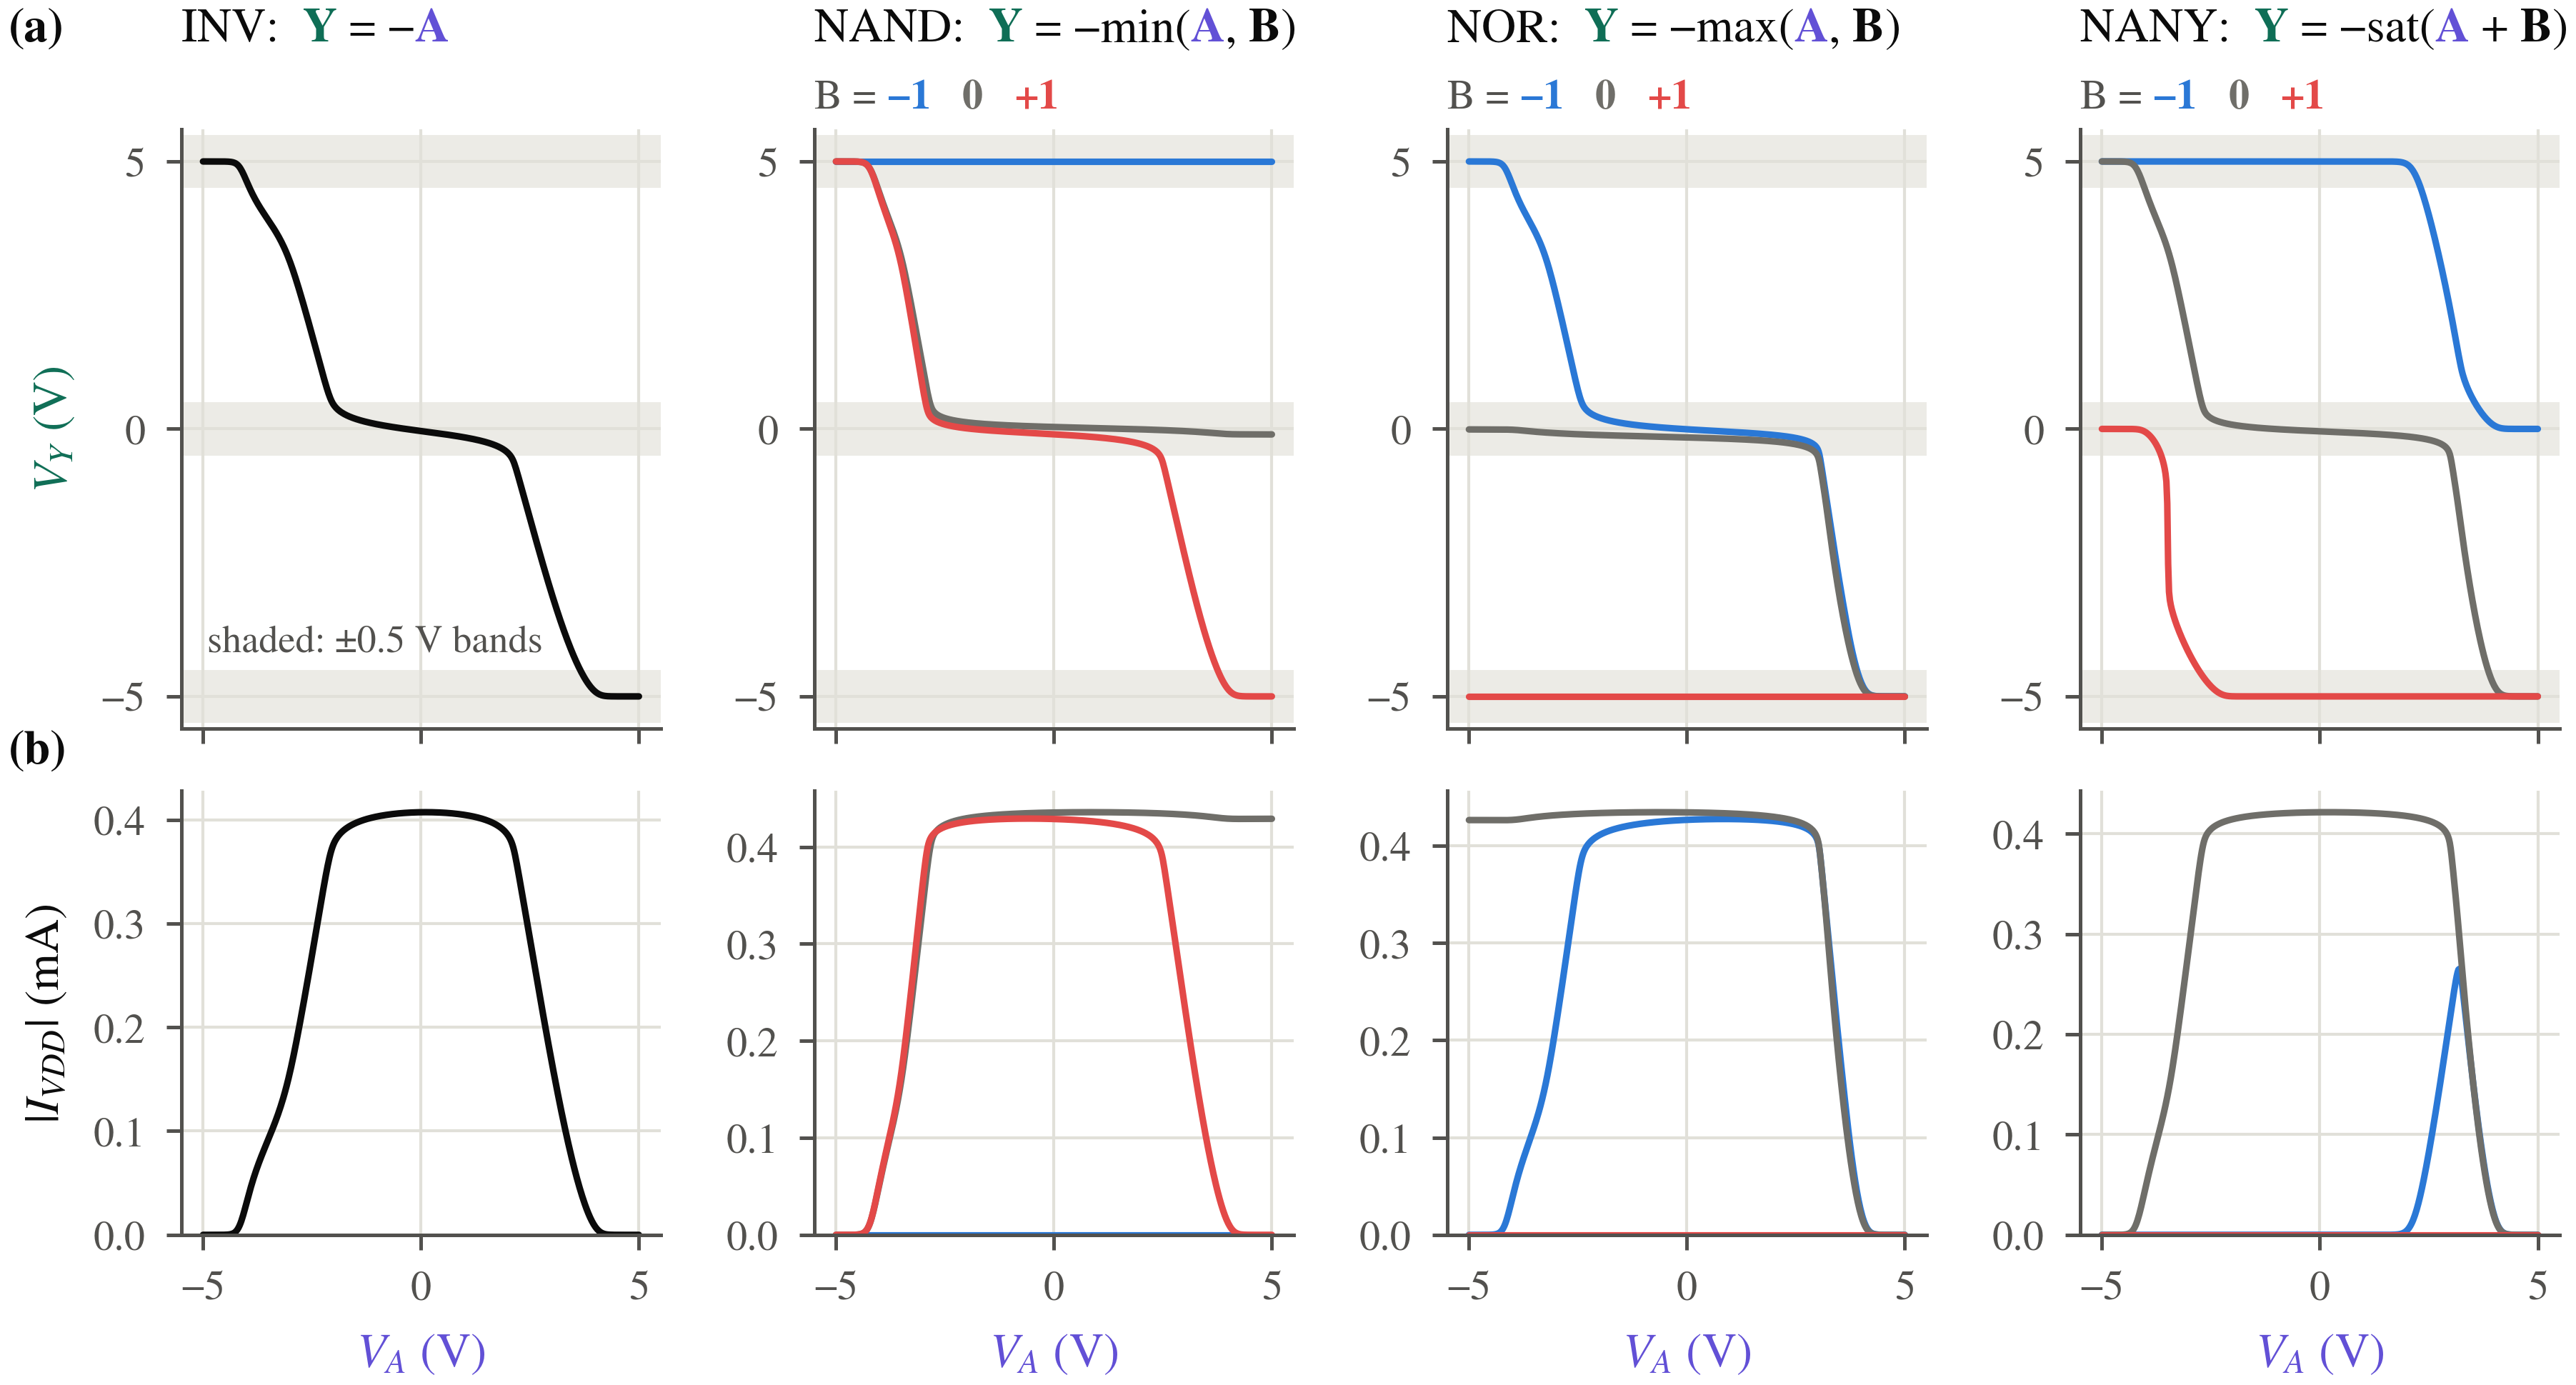

**DC behavior of the ternary logic cells** (a) Output voltage and (b) absolute
VDD current versus input A for the extracted INV, NAND, NOR and NANY cells at
27 °C, with B held at each trit level where applicable.
At its middle input, INV draws 0.4072 mA from VDD,
corresponding to 4.072 mW of signed total rail power;
shading marks the ±0.5 V output acceptance bands.

> **What this shows.** At a middle input, the extracted INV settles at
> -0.03954 V and draws 0.4072 mA from
> VDD at 27 °C. Its signed rail powers sum to
> 4.072 mW with constant input.

The schematic-dimension divider estimate gives -0.02066 V and
4.432 mW, compared with -0.03954 V and
4.072 mW in the matching schematic DC calculation.

At $a=0$, both $\min(a,-a)$ and $\max(a,-a)$ equal zero.
That example is enough to reject Boolean complementation as a synthesis rule.


`examples/gates.tv`

```verilog
// The four primitive cells, written as TritVerilog expressions.
// Trits are -1, 0, +1; '~' negates, '&' is min, '|' is max.
module gates(input  trit a, b,
             output trit inva, nandab, norab, nanyab);
  assign inva   = ~a;          // INV  : -a
  assign nandab = ~(a & b);    // NAND : -min(a, b)
  assign norab  = ~(a | b);    // NOR  : -max(a, b)
  assign nanyab = nany(a, b);  // NANY : -sat(a + b)
endmodule
```


In [ ]:
gates = flow.load(ROOT/"examples/gates.tv", "gates")       # the definition shown above
t = gates.truth_table()                                    # all nine input pairs, ideal trits
curve = dc_transfer((CELLS_DIR/"out/INV/INV.ext.spice").read_text(), "INV", ["A"], ["Y"], "A",
                    fixed_trits={}, step_v=0.02)["data"]   # extracted INV layout, DC sweep in ngspice
i0 = int(np.argmin(abs(curve["v-sweep"])))
print(f"A = 0 V:  Y = {1e3*curve['v(y)'][i0]:.1f} mV,  supply current = {1e3*abs(curve['i(vdd)'][i0]):.3f} mA")


In [ ]:
#@title Chapter 1 checks and the taped-out INV schematic { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('gates', '1. Three levels from ordinary CMOS', requires=[]):
    assert np.array_equal(t["inva"], -t["a"])
    assert np.array_equal(t["nandab"], -np.minimum(t["a"], t["b"]))
    assert np.array_equal(t["norab"], -np.maximum(t["a"], t["b"]))
    assert np.array_equal(t["nanyab"], -np.clip(t["a"]+t["b"],-1,1))
    details_html("Gate truth tables", truth_table_html(gates.design))
    for name in ["INV","NAND","NOR","NANY"]:
        body = subcircuits((CELLS_DIR/f"out/{name}/{name}.spice").read_text())[name.lower()]["body"]
        assert ("VMID" in body.upper()) == (name == "NANY"), name
    # Same public DC call and zero-input sample as the static gate figure.
    assert abs(curve["v-sweep"][i0]) < 1e-9
    assert abs(curve["v(y)"][i0]-paper["inv_dc"]["output_v"]) < 1e-8
    details_html("Taped-out INV schematic and exported source",schematic_gallery(
        ROOT/"notebook/assets/schematics",names=["INV"],selected="INV"))


## 2. Sizing sets the middle level

Sizing changes both sides of the divider. A stronger pull-down lowers the
middle output; a stronger pull-up raises it. Increasing both series resistors
reduces static current, while MOS asymmetry still affects the voltage.
Compare inverter transfer curves at fixed MOS sizes, then read the error/current
scatter plots for INV and NANY. The circled points mark the adopted reference
dimensions.

**Predict first.** For the conducting MOS devices, take on-resistance as
inversely proportional to $W/L$. Apply the divider from the previous chapter
before looking at the new SPICE curve.

$$
r_{\mathrm{on}}'\simeq r_{\mathrm{on}}
\frac{(W/L)_{\mathrm{adopted}}}{(W/L)'},\qquad
I'=\frac{V_{DD}-V_{SS}}{R_u'+R_d'},
$$

$$
\Delta V_Y\simeq
(V_{DD}-V_{SS})\frac{R_u\Delta R_d-R_d\Delta R_u}{(R_u+R_d)^2}.
$$



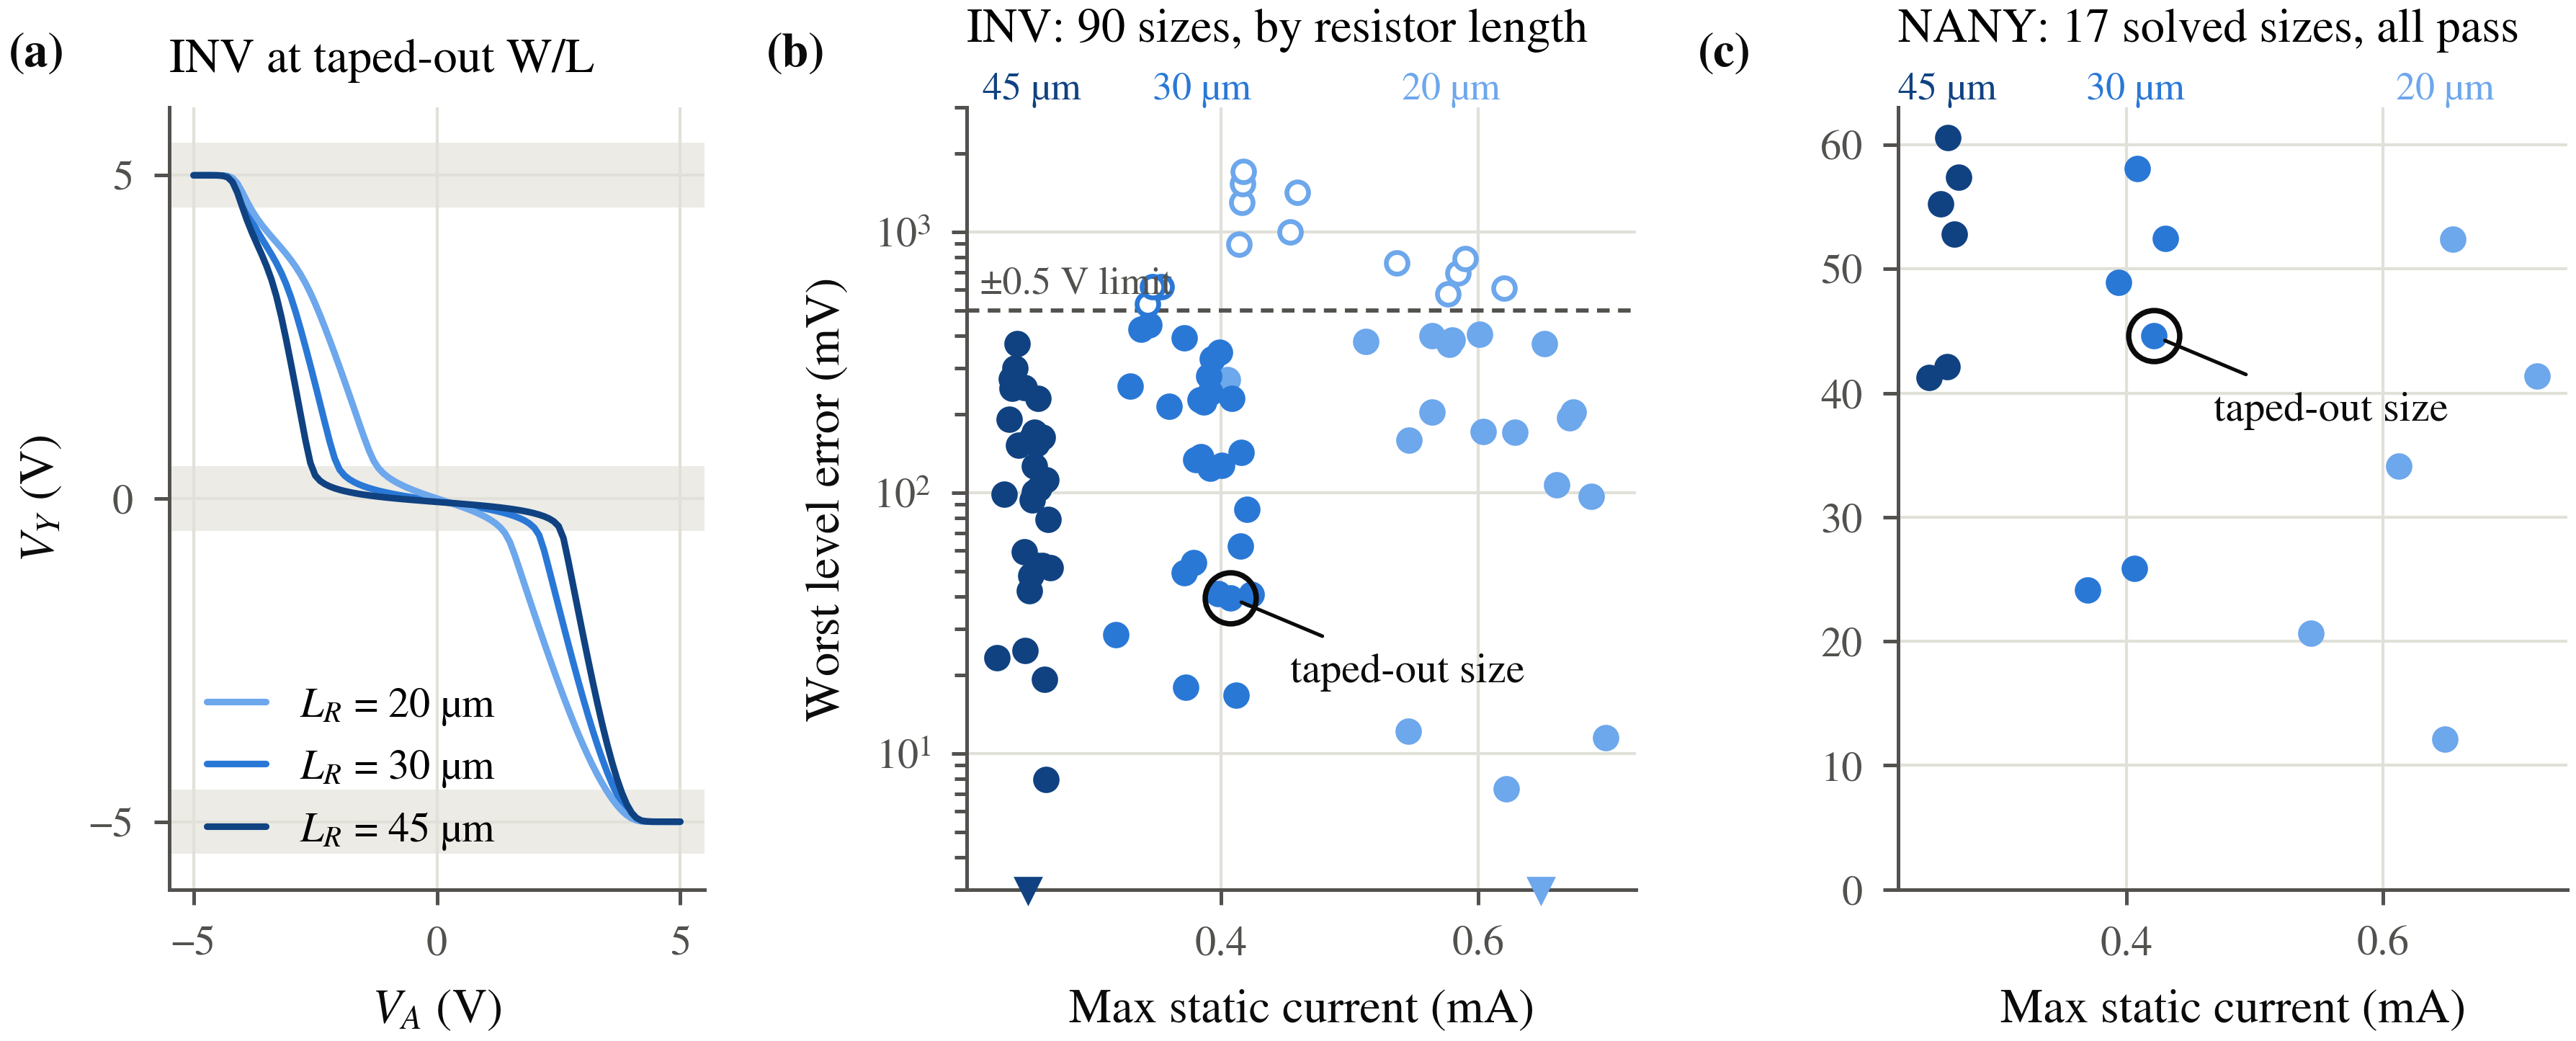

**Dimensions control middle-level accuracy and standing current** (a) INV
transfer curves for resistor lengths 20, 30, 45 µm
at the adopted MOS dimensions; (b,c) worst discrete-state level error versus
maximum absolute rail current for 90 finite INV and
17 finite NANY results.
Filled and open markers distinguish errors within and outside
±0.5 V, inverted triangles place errors below
3 mV at the display floor, and outer rings identify
the dimensions used in the reference design.

> **What this shows.** The scatter plots contain 90
> finite INV results and 17 finite NANY results.
> At the circled INV size, worst logical level error is
> 39.54 mV and maximum absolute rail current is
> 407.2 µA; the corresponding NANY values are
> 44.6 mV and 421.4 µA.

Lengthening both INV resistors from 30 to
45 µm at fixed MOS dimensions, the divider predicts an
upward middle-level shift of 7.984 mV; schematic SPICE
instead gives -12.9 mV. The hand model gets the reduction
in current right, but misses the sign of this small voltage shift. It keeps
only geometric resistor resistance and a constant MOS on-resistance. Both
F_RR substrate terminals actually tie to VDD, while the two resistors' signal
terminals sit at different voltages, so their bias-dependent resistance
corrections differ; the MOS also operate nonlinearly. The measured trade-off
is current falling from 407.2 to
260.7 µA while worst level error rises from
39.54 to 52.44 mV.


In [ ]:
from tritflow.sim.sizing import load_grid
sizing_grids = {cell: load_grid(cell) for cell in ("INV", "NANY")}  # precomputed W/L/R sweeps
gi = sizing_grids["INV"]
adopted = gi["rows"][gi["adopted_index"]]                           # the taped-out size
hand = divider(adopted["dimensions"], PDK_ROOT)                     # predict first ...
table([["INV at zero input", "Hand estimate", "SPICE"],
       ["Output (V)", hand["output_v"], zero_dc(adopted)["output_v"]["Y"]],
       ["Static power (mW)", hand["power_w"]*1e3, rail_power(zero_dc(adopted), gi["conditions"]["supplies_v"])*1e3]])
show(sizing_slider(gi, PDK_ROOT))                                   # ... then explore every simulated size


In [ ]:
#@title Chapter 2 details: resistor-length candidates at the taped-out MOS sizes { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('sizing', '2. Sizing sets the middle level', requires=[]):
    # Hold MOS sizes fixed: these are actual simulated RR candidates.
    rr_candidates = sorted((r for r in gi["rows"] if r["dc"] and
        all(r["dimensions"][k] == adopted["dimensions"][k] for k in ("MP","MN"))),
        key=lambda r:r["dimensions"]["RP"]["l_um"])
    table([["Common RR length (µm)","Worst level error (mV)","Max |rail I| (µA)","Reference"]]+[
        [r["dimensions"]["RP"]["l_um"],r["max_error_v"]*1e3,r["max_static_current_a"]*1e6,
         "taped out" if r["is_adopted"] else ""] for r in rr_candidates])


## 3. Taped-out circuits become placeable cells

A router needs a cell boundary, legal pin landings and obstacles as well as
a circuit. These cells share a height and carry VDD, VMID and VSS horizontally
across the row. Compare the original and adapted NANY at the same scale, then
follow each rail across the abutted row. Device outlines identify the pull-up,
pull-down, clamp and resistor groups.

Internal M2 and vias appear in the routing obstacles. Signal pins sit on M1
where a vertical M2 route can reach them through a via. Cells may face forward
or reflect left to right while preserving the rail order. TIE cells supply
constants through finite resistance; FILL continues rails and wells through gaps.



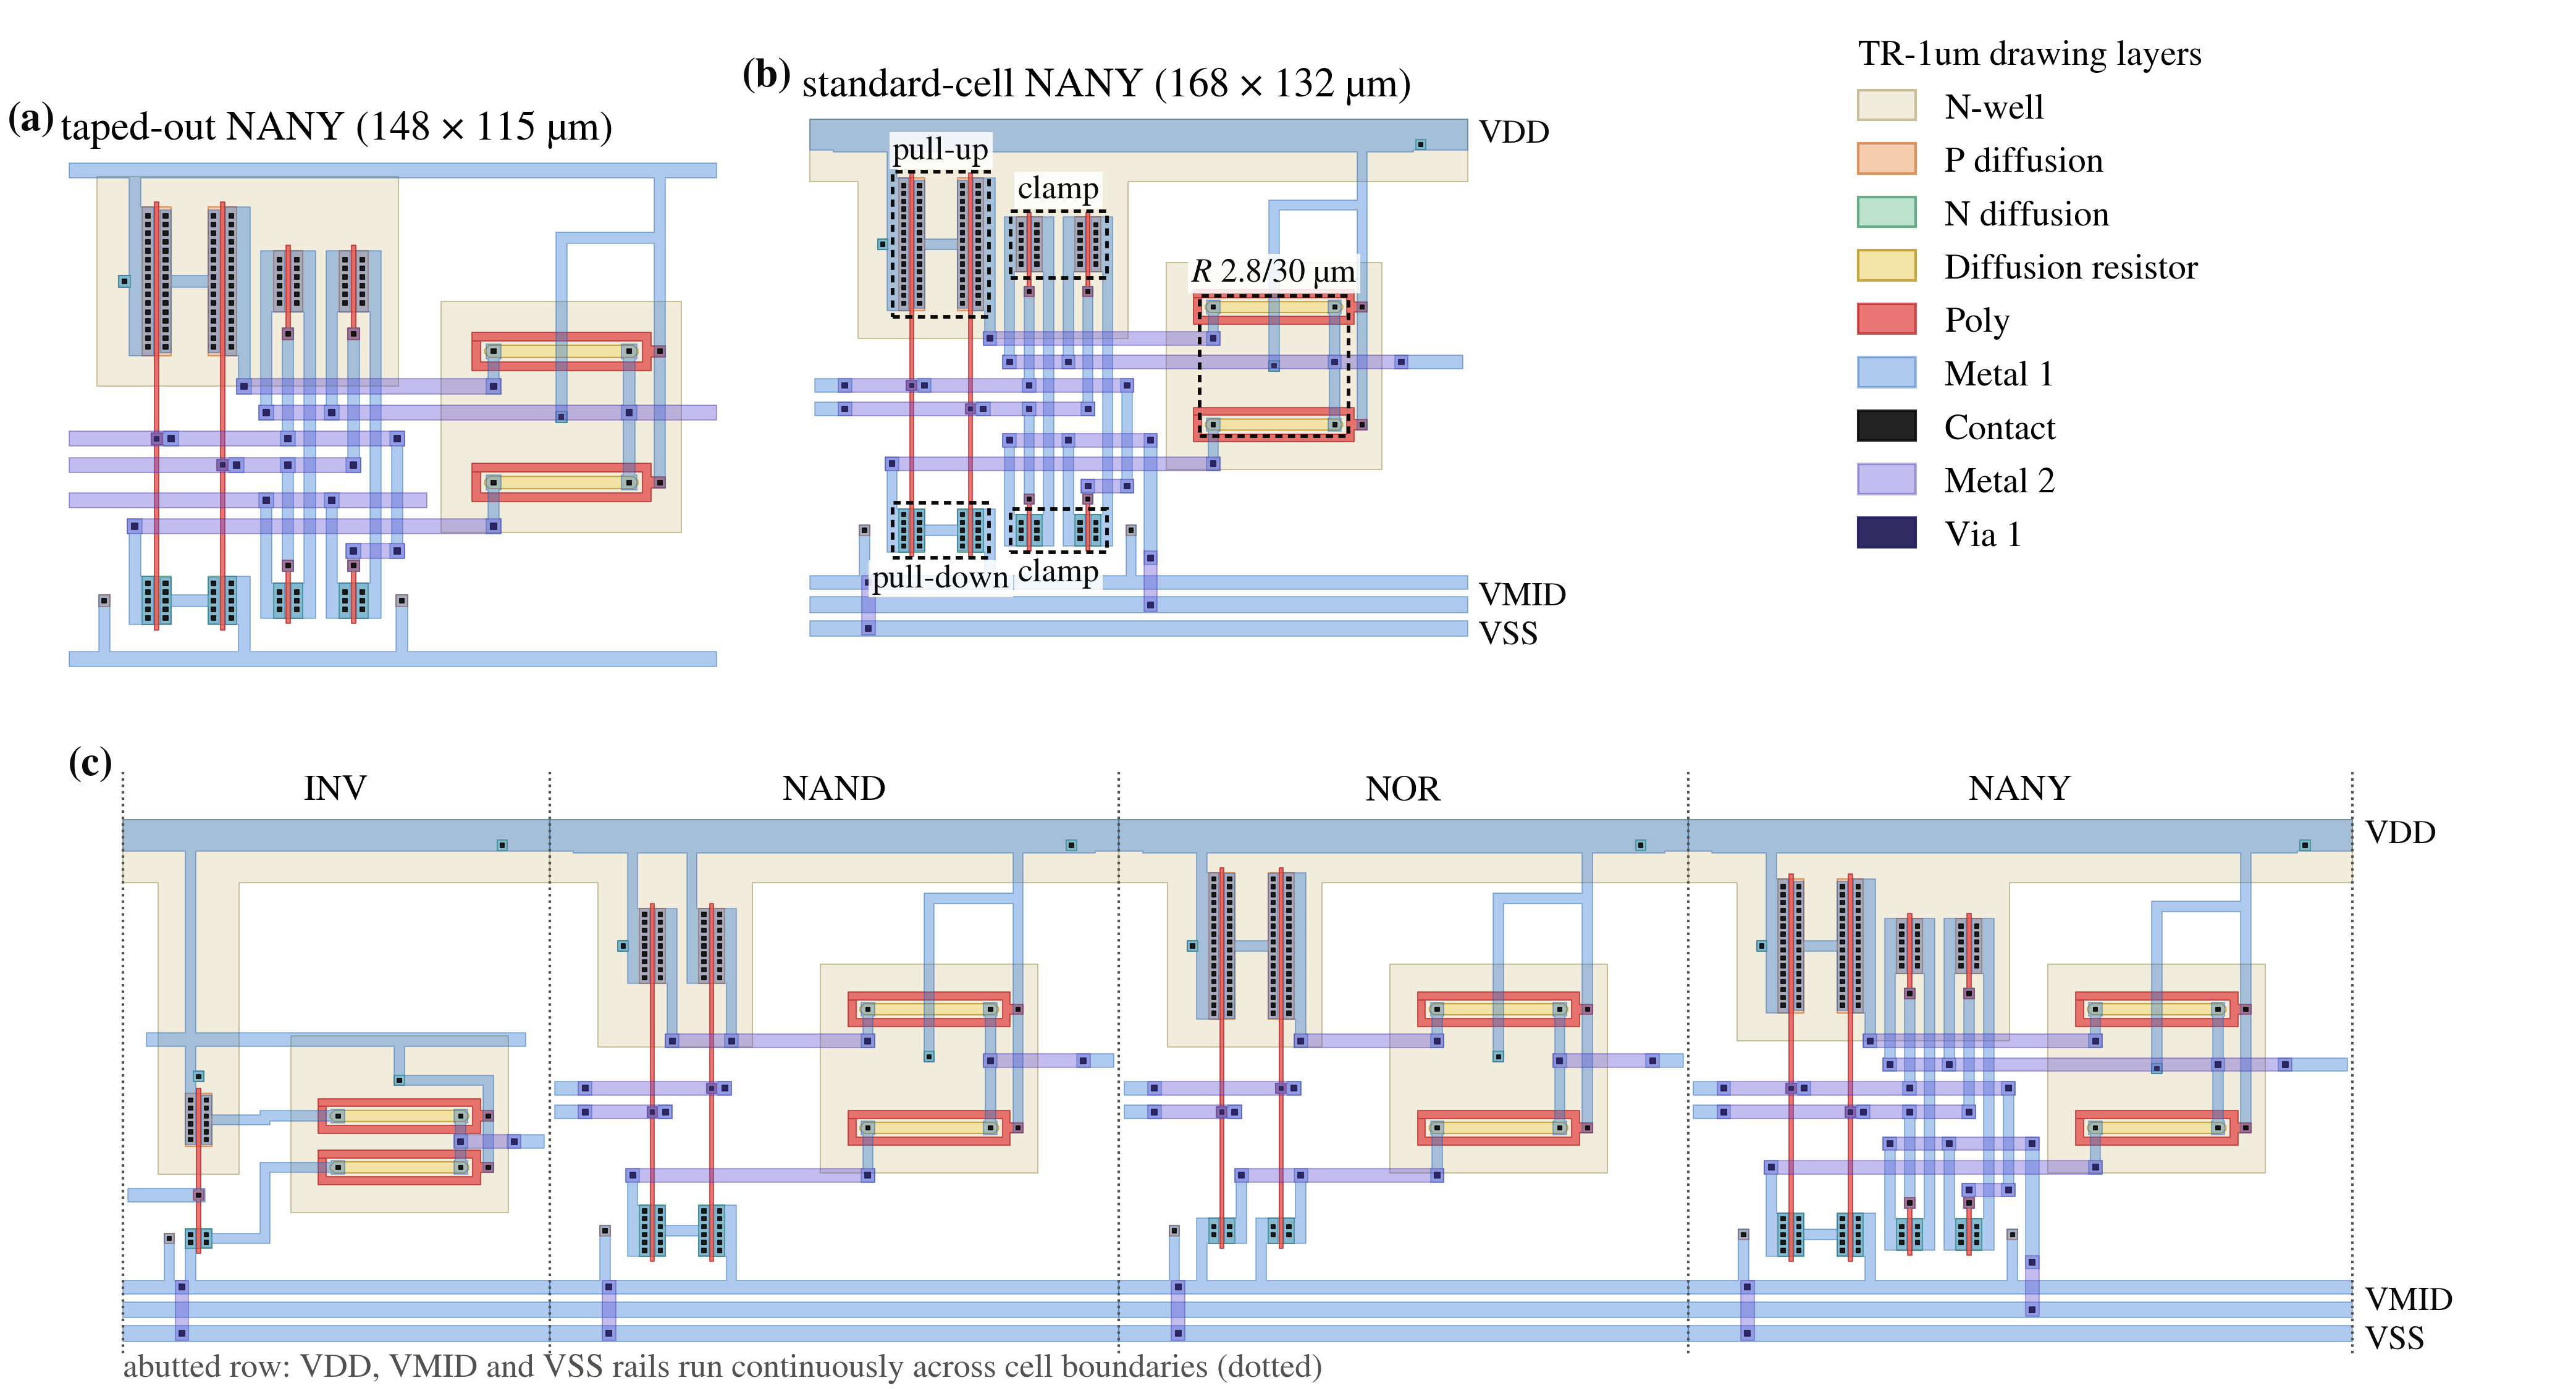

**Adapting the reference NANY to a three-rail cell row** (a) The taped-out
reference layout occupies 148 × 115 µm; (b) the adapted
cell retains its circuit and device sizes in a 168 ×
132 µm footprint, with the device groups and supply rails labelled.
(c) An abutted row of 4 logic cells carries VDD, VMID
and VSS continuously across the indicated cell boundaries.

> **What this shows.** NANY grows from 148 × 115 µm to
> 168 × 132 µm, or 1.303 times the
> reference footprint, while retaining its circuit and device sizes.
> VDD, VMID and VSS continue across all 4 cells in the row.

The cell checks and row-abutment results are available in Appendix B.


In [ ]:
library = json.loads((CELLS_DIR/"out/library.json").read_text())
abstracts = {c["name"]: json.loads((CELLS_DIR/"out"/c["abstract"]).read_text()) for c in library}
print({name: f"{a['width']:g} × {a['height']:g} µm" for name, a in abstracts.items()})
mapping = device_mapping("NANY", selected="XCN1")       # LVS-matched schematic devices on the real GDS
show(highlight_devices(mapping, {"XCP1", "XCN1"},
                       title="NANY: Y → XCP1/XM6 → c1 → XCN1/XM7 → VMID, A=−1 B=+1"))


In [ ]:
#@title Chapter 3 checks: template, clamp devices and cell qualification { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('cells', '3. Taped-out circuits become placeable cells', requires=[]):
    template = json.loads((CELLS_DIR/"template.json").read_text())
    generation = json.loads((CELLS_DIR/"out/generation.json").read_text())
    assert {a["height"] for a in abstracts.values()} == {template["height"]}
    assert generation["height_um"] == template["height"]

    cell_dimension_rows = ([["Cell", "Width × common height (µm)", "Area (µm²)", "Free full-height M2 tracks"]]+
          [[name, [a["width"],a["height"]], a["width"]*a["height"], a["free_M2_tracks"]["count"]]
           for name,a in abstracts.items()])
    abstract = json.loads((CELLS_DIR/"out/NANY/NANY.abstract.json").read_text())
    # Highlight both conducting devices of the zero-level clamp. These are device
    # outlines, not an invented extracted current-density or wire-current map.
    clamp_devices = {"XCP1","XCN1"}
    clamp_body = subcircuits((CELLS_DIR/"out/NANY/NANY.spice").read_text())["nany"]["body"]
    clamp_terminals = {fields[0]:fields[1:5] for fields in map(str.split,clamp_body.splitlines()) if fields}
    assert clamp_terminals["XCP1"] == ["c1","A","Y","VDD"]
    assert clamp_terminals["XCN1"] == ["c1","B","VMID","VSS"]
    clamp_character = json.loads((CELLS_DIR/"out/NANY/NANY.char.json").read_text())
    assert hashlib.sha256((CELLS_DIR/"out/NANY/NANY.ext.spice").read_bytes()).hexdigest() == clamp_character["source_sha256"]
    clamp_dc = next(r for r in clamp_character["dc"] if r["input_trits"] == [-1,1])
    assert clamp_dc["passed"] and abs(clamp_dc["output_v"]["Y"]) <= PASS_BAND
    assert clamp_devices <= {r["name"] for r in mapping.rows}
    evidence("Device correspondence and W/L",mapping.rows)

    qualification = CELLS_DIR/"out/verify_report.json"
    if qualification.is_file():
        report = json.loads(qualification.read_text())
        assert report["passed"]
        assert all(hashlib.sha256((PDK_ROOT/name).read_bytes()).hexdigest() == value
                   for name,value in report["deck_sha256"].items()), "cell qualification uses a different PDK"
        for cell, artifacts in report["artifact_sha256"].items():
            for suffix, expected_hash in artifacts.items():
                assert hashlib.sha256((CELLS_DIR/f"out/{cell}/{cell}.{suffix}").read_bytes()).hexdigest() == expected_hash
        cell_qualification_rows = ([["Cell", "Recorded DRC clean", "Recorded LVS qualification", "LVS method"]]+[
            [name, result["drc"]["passed"], result["lvs"]["passed"],
             result["lvs"].get("method","strict device/port comparison")]
            for name,result in report["cells"].items()])
        if "FILL" in report["cells"]:
            evidence("FILL qualification", report["cells"]["FILL"]["lvs"]["explanation"])
        evidence("Recorded qualification scope", report["scope"])
    else:
        raise FileNotFoundError("Required pinned-PDK cell qualification: "+str(qualification))


## 4. Describe signed arithmetic in TritVerilog

Balanced ternary represents a signed integer without a separate sign bit:
digit $i$ has weight $3^i$. The half adder combines two trits; the full
adder also accepts a carry. Read the shared HDL beside the mapped gates and
follow the illustrated sum-and-carry equality. A generate loop
connects these slices into the wider adder from the opening example.

$$
a+b+{c}_{in}=s+3{c}_{out},\qquad
A+B+{c}_{in}=\sum_{i=0}^{N-1}s_i3^i+{c}_{out}3^N.
$$

The illustrated inputs satisfy $1+1+0=(-1)+3\cdot(+1)$.
The complete truth-table check below uses integer addition independently
of the gate equations.

The HDL supplies `trit`, vectors, parameters, named module connections and
generate loops. Its `~`, `&`, `|` and `nany` mean sign inversion, minimum,
maximum and negative saturated addition. A literal uses `T` for −1.
Signal addition is built from gates; `+` in the HDL is reserved for integer
parameters and indices.



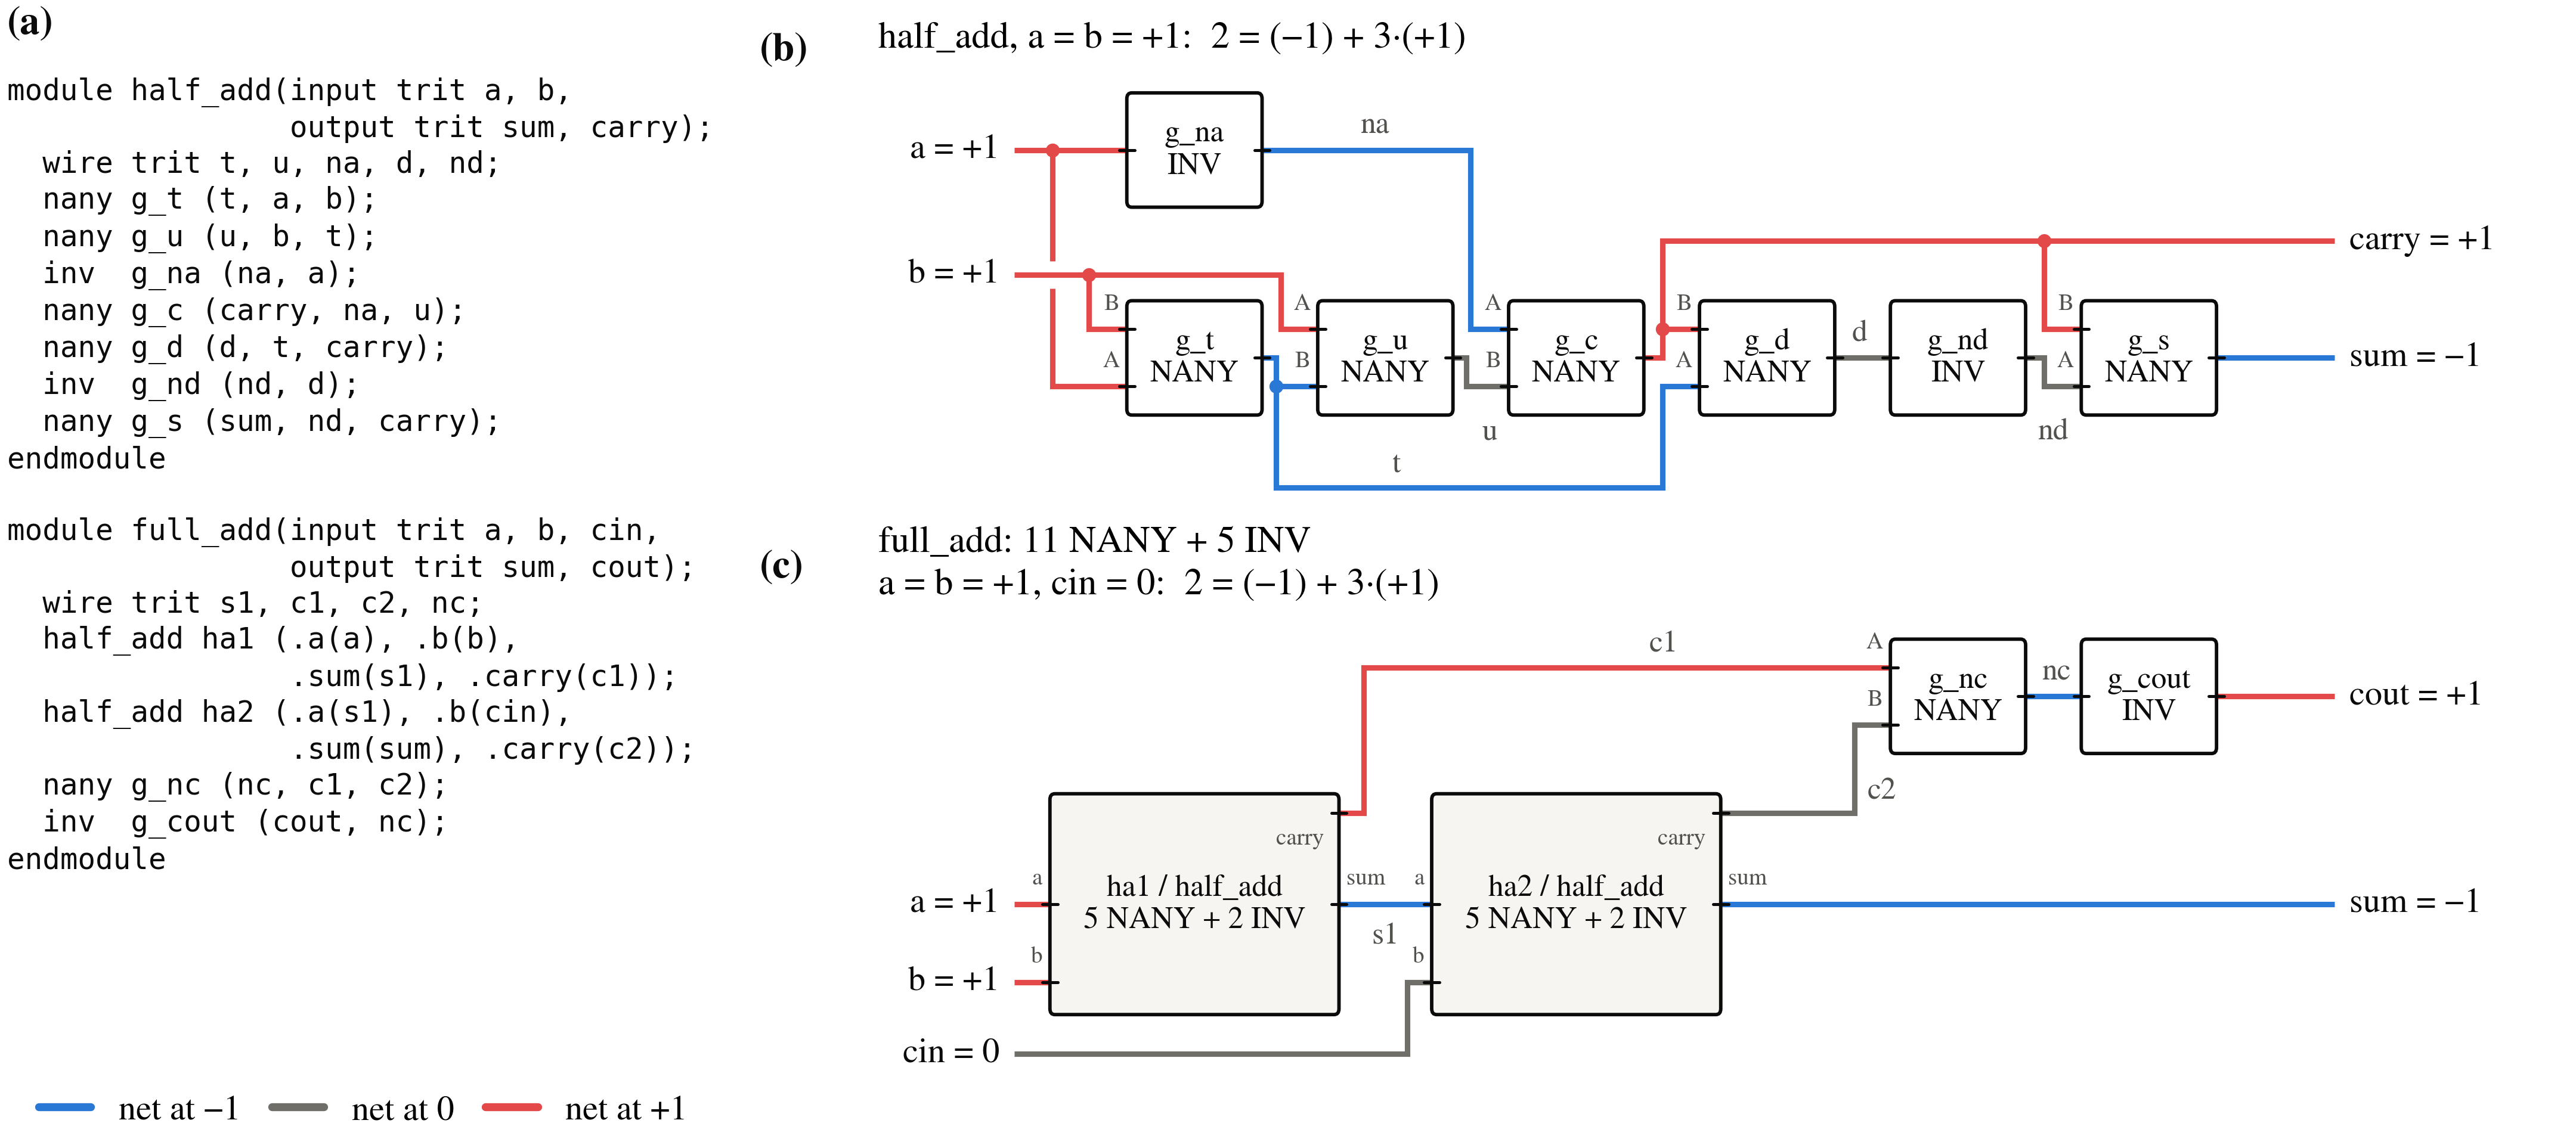

**Arithmetic expressed as ternary cells** (a) Shared half-adder and full-adder
HDL, (b) the mapped half adder with 5 NANY and
2 INV cells, and (c) the full-adder hierarchy with
11 NANY and 5 INV cells.
Net colors show settled negative, middle and positive trits for the illustrated
inputs; the sum and carry preserve the integer total in both examples.

> **What this shows.** The half adder contains 5 NANY and
> 2 INV cells; the full adder contains
> 11 NANY and 5 INV cells.
> The full-adder hierarchy reuses the half adder and combines its carries
> through NANY followed by INV.


`examples/half_add.tv`

```verilog
// Reference: balanced-ternary-logic/HALF_ADDER_SIMULATION.md.
// a + b = sum + 3*carry. Exactly five NANY and two INV cells.
module half_add(input trit a, b, output trit sum, carry);
  wire trit t, u, na, d, nd;
  nany g_t (t, a, b);
  nany g_u (u, b, t);
  inv g_na (na, a);
  nany g_c (carry, na, u);
  nany g_d (d, t, carry);
  inv g_nd (nd, d);
  nany g_s (sum, nd, carry);
endmodule
```

`examples/full_add.tv`

```verilog
`include "half_add.tv"
// Reference: balanced-ternary-logic/FULL_ADDER.md.
// a + b + cin = sum + 3*cout. Exactly eleven NANY and five INV.
module full_add(input trit a, b, cin, output trit sum, cout);
  wire trit s1, c1, c2, nc;
  half_add ha1 (.a(a), .b(b), .sum(s1), .carry(c1));
  half_add ha2 (.a(s1), .b(cin), .sum(sum), .carry(c2));
  nany g_nc (nc, c1, c2);
  inv g_cout (cout, nc);
endmodule
```


In [ ]:
ha = flow.load(ROOT/"examples/half_add.tv", "half_add")
fa = flow.load(ROOT/"examples/full_add.tv", "full_add")
fa_table = fa.truth_table()                                     # all 27 input states
assert np.array_equal(fa_table["a"] + fa_table["b"] + fa_table["cin"], fa_table["sum"] + 3*fa_table["cout"])
ha_counts, fa_counts = ha.synthesize().report()["cells"], fa.synthesize().report()["cells"]
print("half_add:", ha_counts, "  full_add:", fa_counts)


In [ ]:
#@title Chapter 4 checks: cell counts against the taped-out schematics { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('arithmetic', '4. Describe signed arithmetic in TritVerilog', requires=[]):
    details_html("Half-adder exhaustive truth table",truth_table_html(ha.design))
    details_html("Full-adder exhaustive truth table",truth_table_html(fa.design))
    ha_table = ha.truth_table()
    assert np.array_equal(ha_table["a"]+ha_table["b"], ha_table["sum"]+3*ha_table["carry"])
    schematic_sources = json.loads((ROOT/"notebook/assets/schematics/manifest.json").read_text())["schematics"]
    ha_symbols = schematic_sources["half_adder"]["instances_by_symbol"]
    fa_symbols = schematic_sources["full_adder"]["instances_by_symbol"]
    symbol_names = {"INV":"inverter", "NANY":"nany"}
    assert ha_counts == {cell:ha_symbols[symbol] for cell,symbol in symbol_names.items()}
    assert fa_counts == {cell:fa_symbols["half_adder"]*ha_counts[cell]+fa_symbols[symbol]
                         for cell,symbol in symbol_names.items()}
    table([["Circuit", "Cells", "Exhaustive input states"],
           ["half_add",ha_counts,len(ha_table["sum"])], ["full_add",fa_counts,len(fa_table["sum"])]])
    evidence("Ripple-adder HDL", (ROOT/"examples/adder.tv").read_text())


## 5. Follow an expression into cells

Synthesis expands parameters and hierarchy, simplifies ternary expressions,
then maps them to the library. The method cell below draws the mapped half
adder as a schematic: inputs on the left, sum and carry on the right, each
box one library cell (Σ = NANY, triangle = INV). Click an input trit and
every wire recolors to the value it settles to.

Blue, gray and red wires carry −1, 0 and +1. Try a = b = +1: the inputs
add to 2, which the cells write as sum = −1 and carry = +1, because
2 = (−1) + 3·(+1). Follow the shared intermediate nets before checking
the outputs.

A negated minimum maps directly to NAND; a positive minimum adds INV.
The analogous rule uses NOR for maximum. Constants map to TIE cells.
Synthesis removes double inversion, shares common expressions and removes
unused logic using identities that hold for trits. Explicit live gate instances
retain their cell type. Buffer trees limit fanout, and the equivalence check
compares the original source with the final cell network.

> **What this shows.** The mapped half adder has 7 cells:
> 5 NANY and 2 INV.
> At the illustrated positive inputs it produces a negative sum digit and
> a positive carry, preserving the integer total.

The same cell network now supplies both the physical placer and the schematic
reference for layout verification.


In [ ]:
fa_net = fa.synthesize()                         # rewrite → map to cells → equivalence check
print(fa_net.report()["equivalence"])
half_net = flow.load(ROOT/"examples/half_add.tv", "half_add").synthesize()
display(value_selector(half_net))                # click input trits; every net shows its settled value


In [ ]:
#@title Chapter 5 checks: mapping rules and gate-level TritVerilog { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('synthesis', '5. Follow an expression into cells', requires=[]):
    assert fa_net.report()["equivalence"]["passed"]
    assert fa_net.report()["equivalence"]["vectors"] == len(fa_table["sum"])
    table([["Report field", "Value"]]+[[k,v] for k,v in fa_net.report().items()],details="Full synthesis report")
    from tritflow.synth import tritverilog
    evidence("Gate-level TritVerilog", tritverilog(fa_net))
    mapping_cases = [("~a",["INV"]), ("~(a&b)",["NAND"]), ("a&b",["NAND","INV"]),
                     ("~(a|b)",["NOR"]), ("a|b",["NOR","INV"]), ("nany(a,b)",["NANY"]),
                     ("1'tT",["TIEN"]), ("1't0",["TIEZ"]), ("1't1",["TIEP"])]
    mapping_rows = [["HDL expression", "Computed cells"]]
    for expr, expected_cells in mapping_cases:
        mapped = flow.loads(f"module mapping(input trit a,b,output trit y); assign y={expr}; endmodule").synthesize()
        assert sorted(inst.cell for inst in mapped.instances) == sorted(expected_cells)
        mapping_rows.append([expr, mapped.report()["cells"]])
    table(mapping_rows,details="Expression-to-cell mapping checks")


In [ ]:
sch = net.schematic(inputs={"a[0]": 1, "a[1]": 0, "b[0]": 1, "b[1]": 0, "cin": 0}, net_names=True,
                    title="Two-trit adder: mapped hierarchy and settled trits")
display(sch)                                     # the synthesized netlist, drawn as a schematic


## 6. Route signals and feed the standing current

Placement arranges cells in rows with routing channels between them. A seeded
annealing search reduces estimated connection length; a grid router connects
the pins on two metals. M1 signal routes stay in channels, while M2 can cross
cells through unobstructed tracks. The three supplies need enough metal and
feed points to carry the cells' static current.

The router checks connectivity, spacing and via enclosure, then runs the PDK
drawing-DRC deck. LVS compares the extracted devices and connections with
the mapped schematic. The figure colors cells by arithmetic digit and shows
the recorded half-perimeter wirelength during placement.



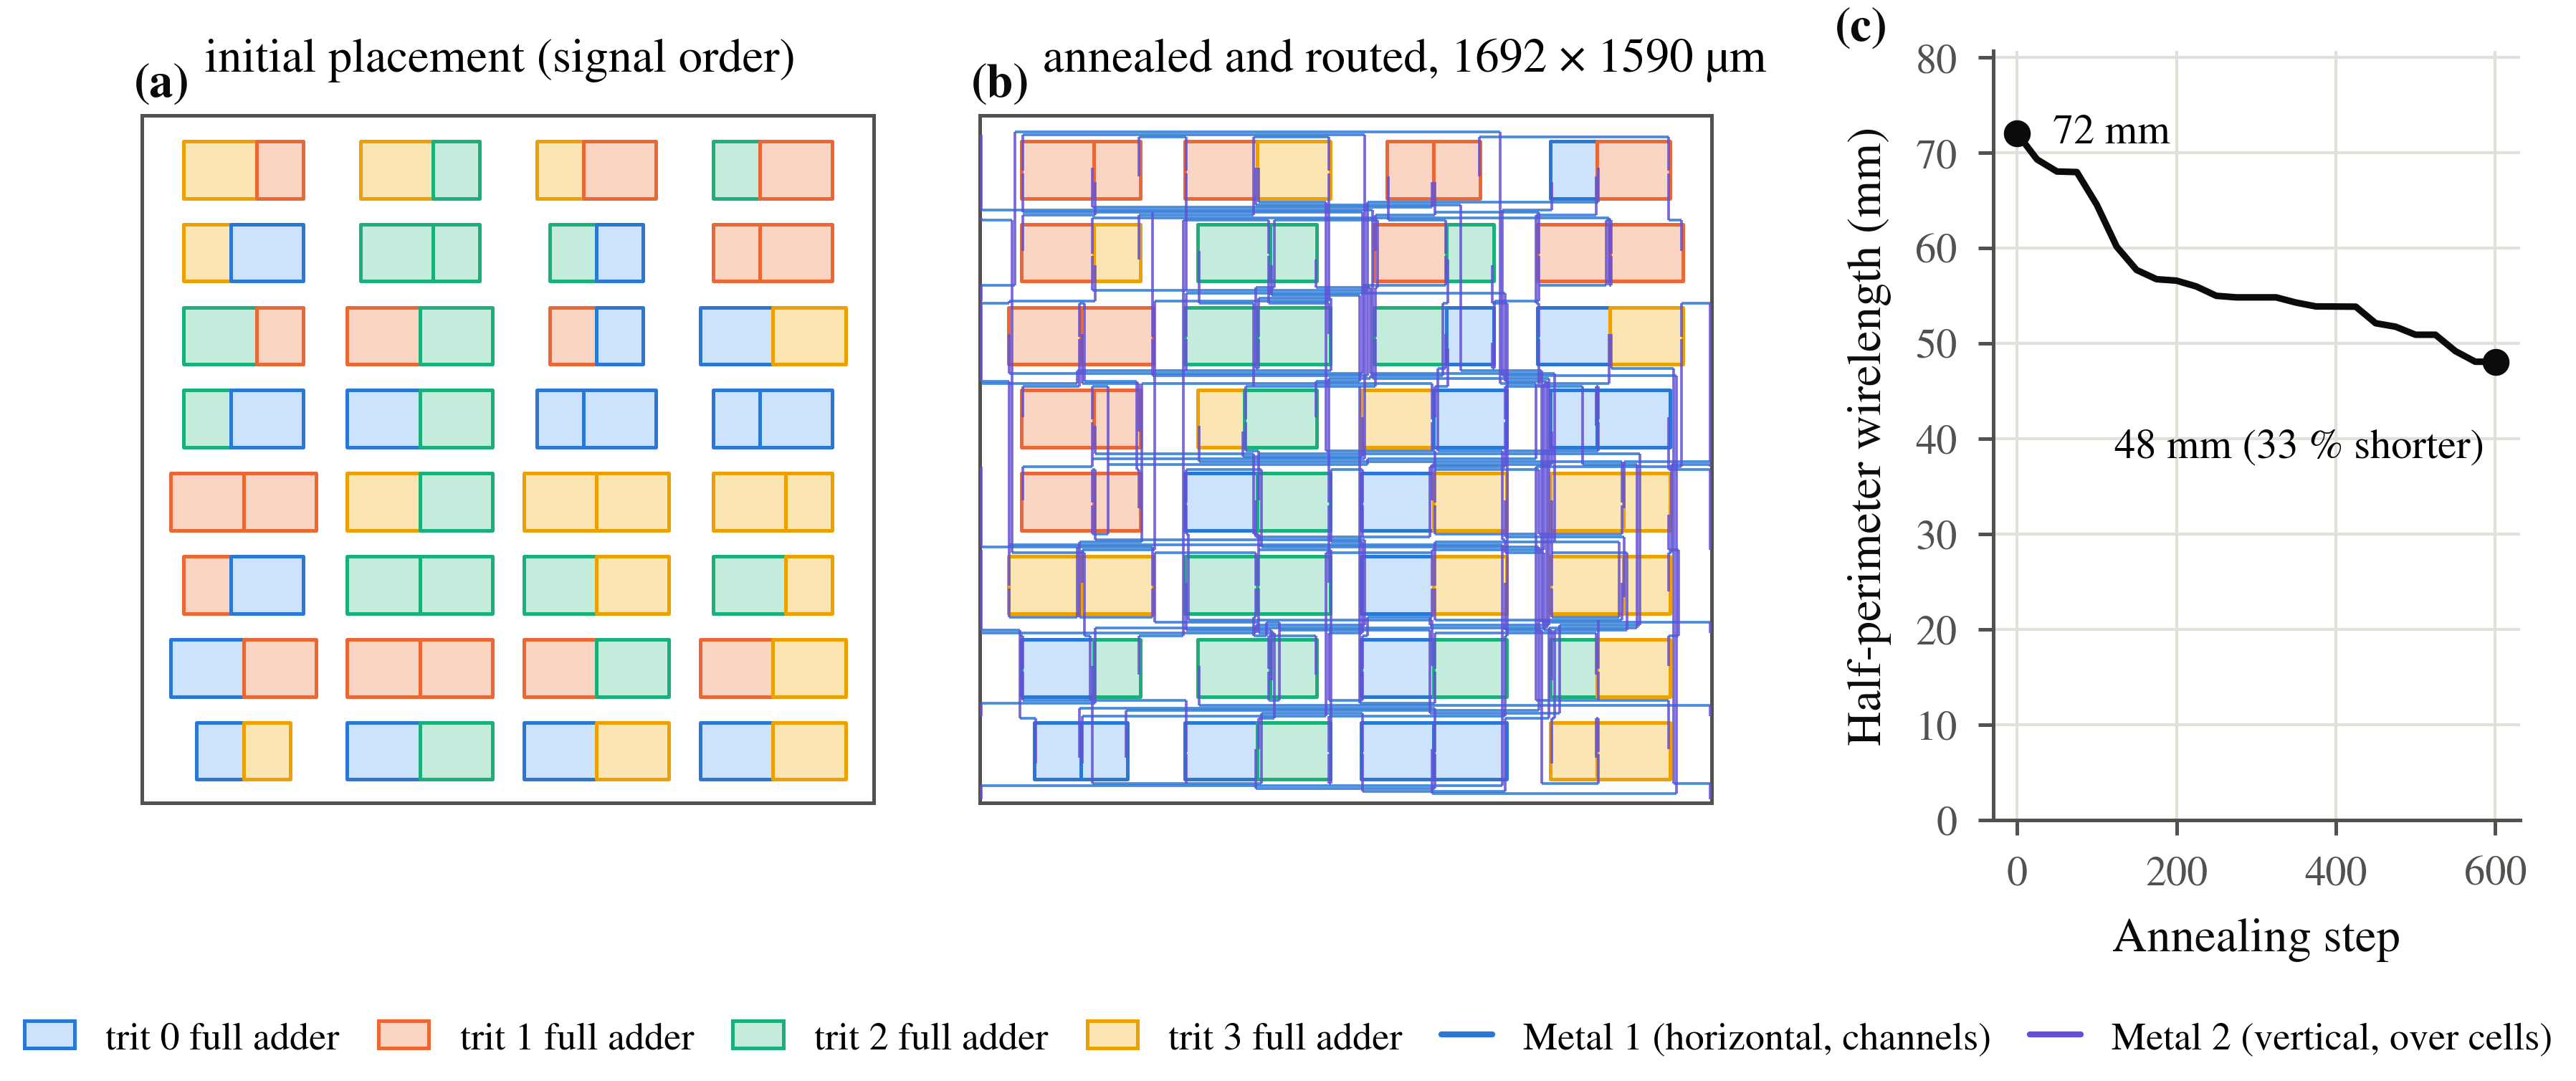

**Placement and routing of the illustrated adder** (a) Initial placement in
signal order, (b) the annealed and routed 4-trit layout
occupying 1692 × 1590 µm in run paper/adder4 · seed 7, and (c) the
recorded cell-terminal HPWL.
Annealing reduces HPWL from 72.04 to
48.07 mm, a 33.27% reduction;
cell colors identify full-adder digits, while the routes distinguish
horizontal M1 in channels from vertical M2 over the cells.

> **What this shows.** The illustrated 4-trit adder occupies
> 1692 × 1590 µm. Cell-terminal HPWL falls from
> 72.04 to 48.07 mm during
> annealing, a 33.27% reduction.

The layout is now the source of both device extraction and wire geometry for
the electrical comparison.


In [ ]:
png = render_gds(lay.gds_path, out/"adder2_demo.layout.png", top=net.top)   # KLayout render of the GDS
display(Image(filename=str(png), width=760))
s = lay.stats
print(f"{s['instance_count']} cells in {s['row_count']} rows · die {s['die_size_um'][0]:.0f} × {s['die_size_um'][1]:.0f} µm"
      f" · utilization {100*s['utilization']:.0f} % · annealing shortened HPWL by {s['hpwl_improvement_pct']:.0f} %")


In [ ]:
#@title Chapter 6 details and an optional floorplan experiment { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('pnr', '6. Route signals and feed the standing current', requires=['opening']):
    table([["Metric", "Two-trit adder"]]+[[k,v] for k,v in lay.stats.items()],details="Full physical statistics")
    assert all(check["clean"] for check in lay.data["checks"].values())
    assert lay.stats["routed_nets"] == len(net.nets())
    assert {p["orient"] for p in lay.data["placements"]} <= {"R0","MY"}
    evidence("Live adder physical checks",lay.data["checks"])
    table([["Initial / final cell-terminal HPWL (µm)",
            [lay.data["history"][i]["hpwl"] for i in (0,-1)]]])
    if EXTENDED:
        show(placement_animation(lay.data))
    if EXTENDED:
        show(routing_progress(lay.data))
    RUN_FLOORPLAN_EXPERIMENT = False  # opt in after changing the controls below
    EXPERIMENT_ROWS, EXPERIMENT_ANNEAL_STEPS, EXPERIMENT_SEED = None, 2400, 7
    if RUN_FLOORPLAN_EXPERIMENT:
        folder = BUILD/"floorplan_experiment"
        def route_experiment():
            routed = net.place_and_route(output_dir=folder, rows=EXPERIMENT_ROWS,
                       anneal_steps=EXPERIMENT_ANNEAL_STEPS, seed=EXPERIMENT_SEED)
            drc, lvs = routed.drc(), routed.lvs()
            assert drc["clean"] and lvs["matched"]
            return {"stats":routed.stats, "drc":drc, "lvs":lvs}
        trial = cache.run("floorplan-experiment", {"net":net.to_json(),"rows":EXPERIMENT_ROWS,
                         "steps":EXPERIMENT_ANNEAL_STEPS,"seed":EXPERIMENT_SEED}, route_experiment,
                         artifacts=[folder/f"{net.top}.gds",folder/f"{net.top}.pnr.json"])
        assert trial["drc"]["clean"] and trial["lvs"]["matched"]
        table([["Measured floorplan experiment",trial["stats"]]])
        show(placement_animation(flow.load_layout(net,folder).data))


## 7. Does the layout still work?

Timing must say when an output becomes a valid trit. Here it is the time from
input-ramp start until the output enters the target's ±0.5 V band
and stays there through the input interval. Compare the same extracted devices
with and without estimated wire capacitance, then increase output load and
adder width. The carry path and static power give two predictions to test.

**Predict first.** Use a single full-adder slice to estimate a ripple path.
Let $t_{c,1}$ be its carry settling and $t_{e,1}$ its slower carry-or-sum
endpoint. Each added digit contributes another carry stage.

$$
t_{\mathrm{hand}}(N)=t_{e,1}+(N-1)t_{c,1}.
$$

For the all-zero input, count the mapped cells and sum their zero-input DC
powers. The rail currents retain SPICE's signed voltage-source convention.

$$
P_c(0)=-\sum_{r\in\{DD,MID,SS\}} V_r I_{r,c}(0),\qquad
P_{\mathrm{hand}}(N)=\sum_c n_c(N)P_c(0).
$$



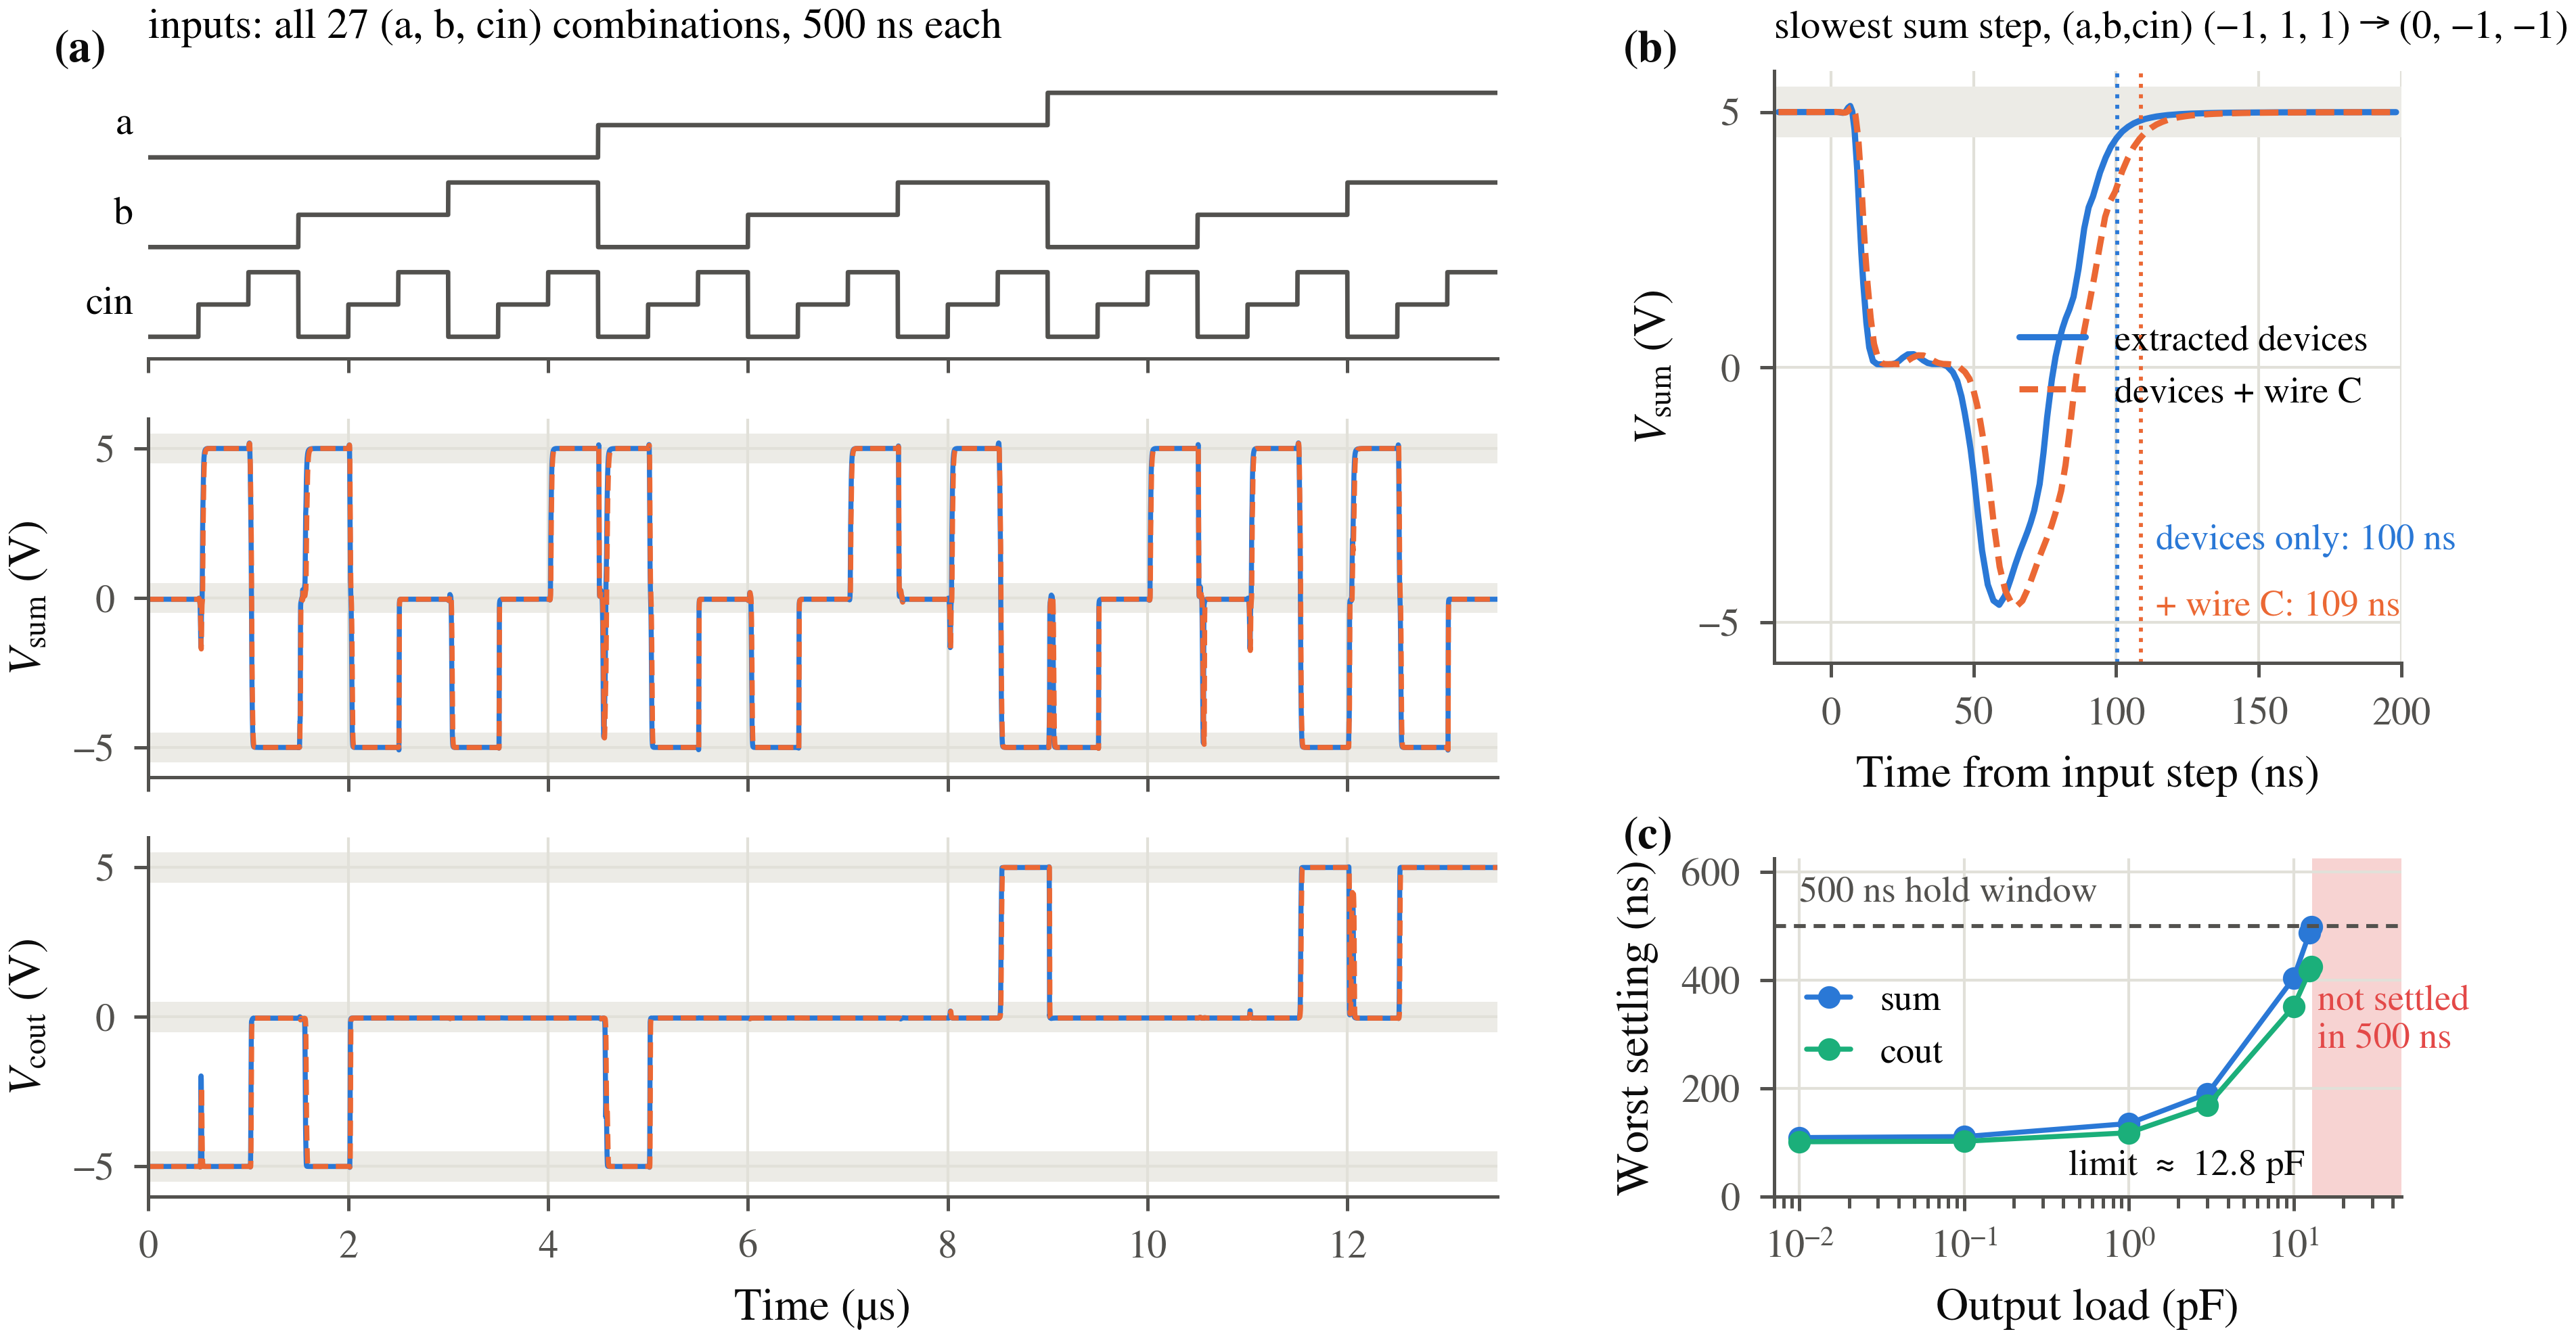

**Full-adder settling and the observed load boundary** (a) The full adder
in run paper/full_add · seed 19 visits 27 input states with
500 ns intervals
and 10 fF per output; device-only and device-plus-wire-C
outputs meet the ±0.5 V criterion.
(b) On the transition with the largest post-wire sum settling, final band
entry changes from 100.3 to 108.6 ns
when estimated wire capacitance is added to the same extracted devices.
(c) The equal-output-load sweep brackets an observed pass and failure between
12.81 and 12.97 pF within its
500 ns intervals.


In [ ]:
pre = lay.extract(wire_c=False).simulate(vectors, load=LOAD_F, expected=adder_reference,
                                         nodeset=guesses, **CONDITIONS)    # same devices, no wire C
for pin, t_post in post["measurements"]["max_settling_s"].items():
    print(f"{pin:7s} devices only {1e9*pre['measurements']['max_settling_s'][pin]:6.1f} ns"
          f"  →  with wire C {1e9*t_post:6.1f} ns")
wire_report = lay.result.net_parasitics()                                 # routed wire C per logical net
routed_sch = sch.annotate(parasitics=wire_report, title="Same schematic: settled trits and routed wire C (fF)")
display(routed_sch)


In [ ]:
#@title Chapter 7 checks: identical devices with and without wire C { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('pre', 'Chapter 7: Does the layout still work?', requires=['opening']):
    assert pre["measurements"]["passed"]
    assert pre["stimulus"]["vectors"] == demo["stimulus"]["vectors"]
    assert pre["stimulus"]["hold_s"] == demo["stimulus"]["hold_s"]
    assert pre["stimulus"]["step_s"] == demo["stimulus"]["step_s"]
    assert routed_sch.scene is sch.scene
    evidence("Schematic wire-C scope (excludes receiving-pin C)",wire_report["assumptions"])
    if EXTENDED:
        for load in [10e-15,1e-12]:
            loaded = cache.run(f"adder2-load-{load:g}", {"vectors":vectors,"load":load}, lambda:
                lay.extract().simulate(vectors, load=load, expected=adder_reference,
                                       hold_s=2e-6, step_s=2e-9, timeout=180))
            assert loaded["measurements"]["passed"], loaded["measurements"]
            print(load, loaded["measurements"]["passed"], loaded["measurements"]["max_settling_s"])


The middle level has a standing cost: 4.17 mW per mapped cell for this adder mix, reaching 0.4 W at 6 trits. Sizing trades current against voltage accuracy.

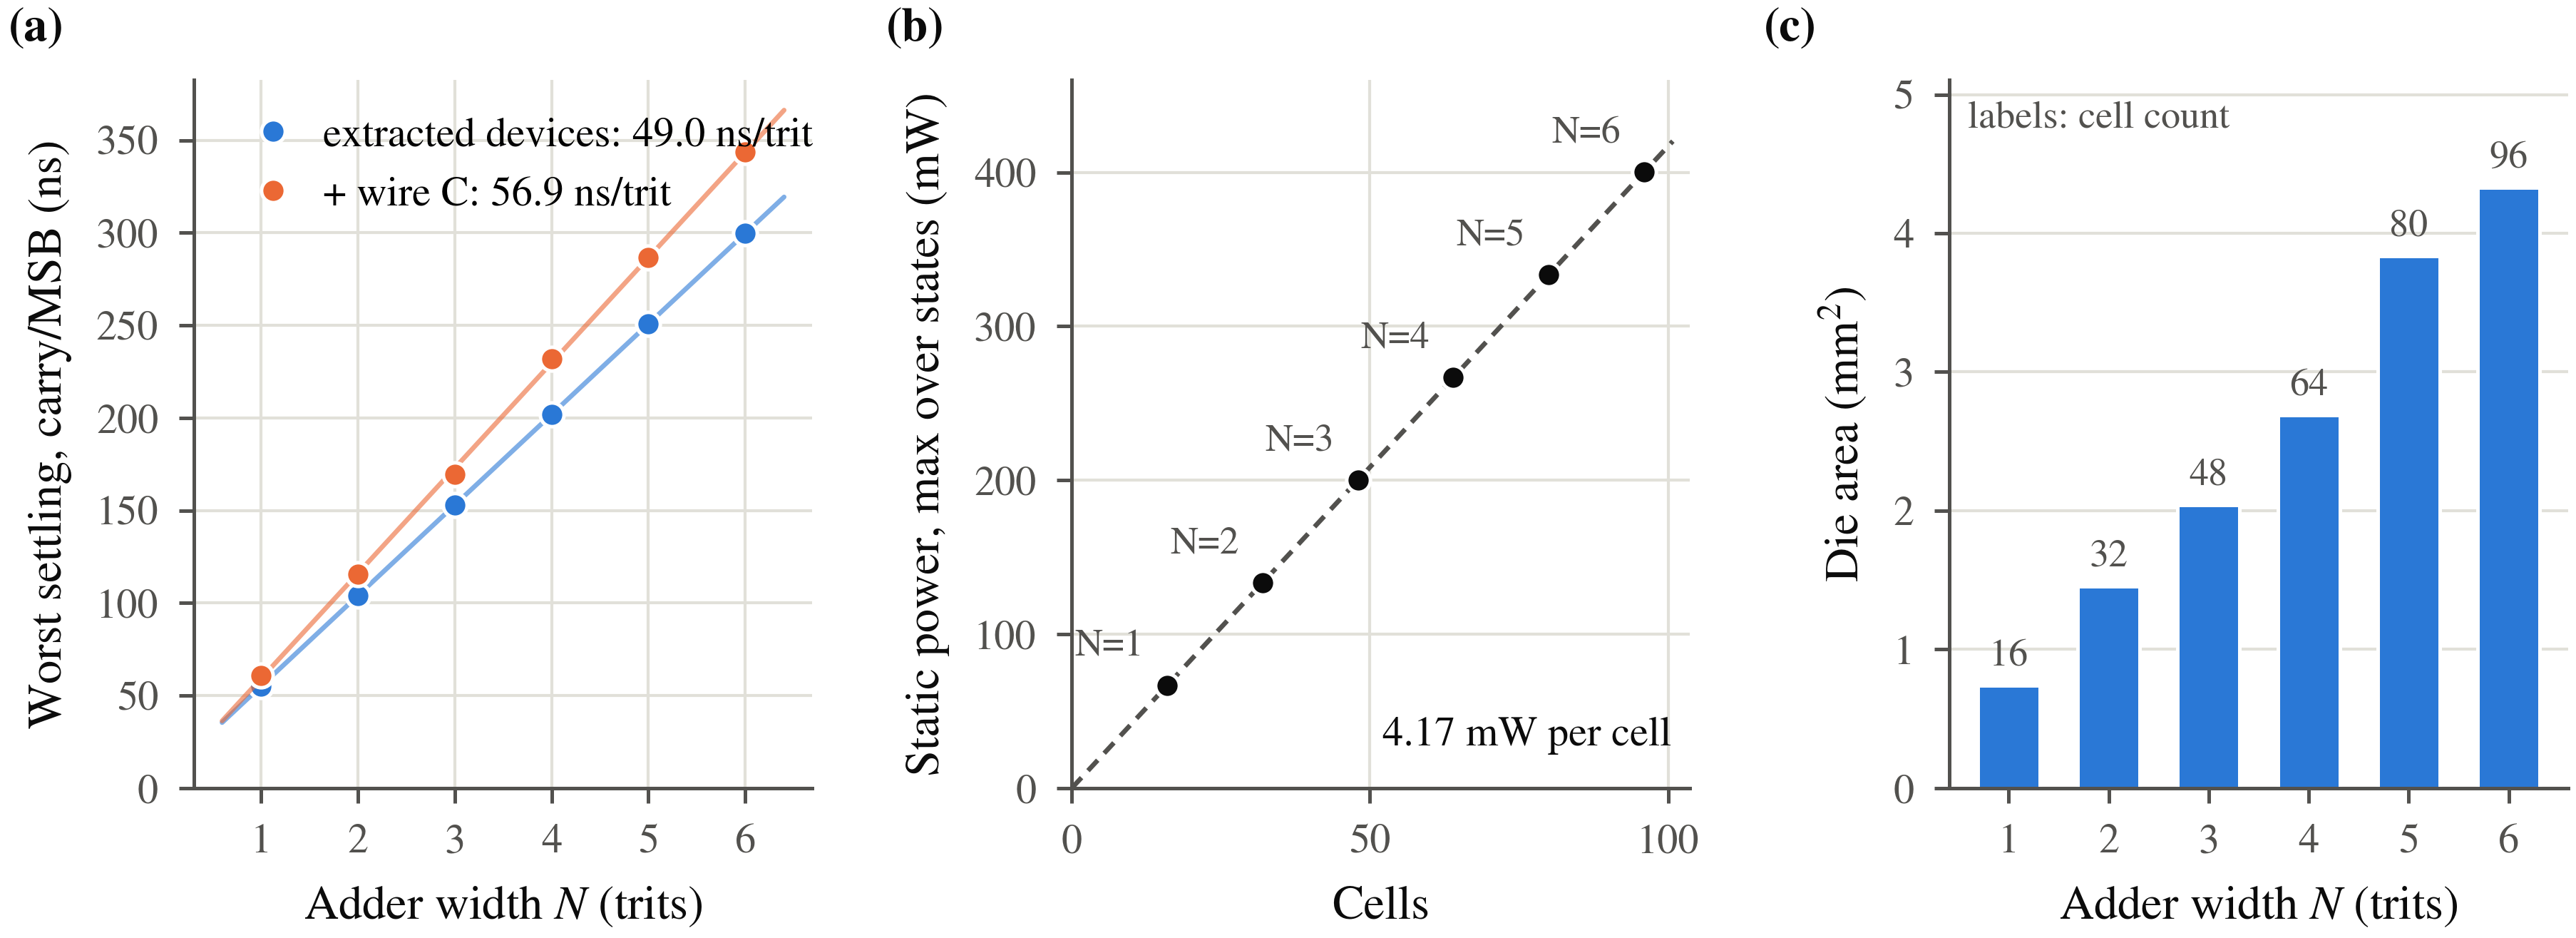

**Ripple-adders generated from one parameterized HDL source** Adders of
width 1–6 trits are synthesized,
routed, drawing-DRC/LVS checked and simulated at 10 fF
per output under nominal models (run family width-sweep · seed 7).
(a) Fits to the recorded carry-endpoint settling give
48.95 ns/trit for extracted devices alone and
56.88 ns/trit with estimated wire capacitance.
(b) The tested-state DC-power maxima give an effective
4.169 mW per mapped cell for this adder mix;
(c) die area and cell count show the physical cost of increasing width.

> **What this shows.** With 27 full-adder states and
> 500 ns input intervals, the load test brackets a pass and failure
> between 12.81 and 12.97 pF per output.
> Over widths 1–6, fitted
> carry-endpoint settling slopes are 48.95 ns/trit for
> devices alone and 56.88 ns/trit with wire capacitance.
> The tested-state static-power fit gives 4.169 mW per
> mapped cell, reaching 400.2 mW at width 6.

Compare the hand estimates with the widest displayed adder. The delay
comparison uses the same carry and most-significant-sum endpoints as the plot;
the power comparison uses a separate all-zero DC state.

<div style="display:block;width:100%;min-width:0;max-width:100%;overflow-x:auto;contain:inline-size;box-sizing:border-box;">
<table width="100%" style="width:100%;min-width:0;max-width:100%;table-layout:fixed;border-collapse:collapse;">
<tr><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Quantity</th><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Hand estimate</th><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">SPICE</th></tr>
<tr><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Carry-path settling, devices only (ns)</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">278.9</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">299.7</td></tr>
<tr><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">All-zero static power (mW)</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">400.2</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">400.2</td></tr>
</table>
</div>

The current flows with the inputs held still; reducing switching frequency
alone does not remove it. The separate rail-network results appear in Appendix B.


In [ ]:
#@title Chapter 7 recorded width and load campaigns { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('published', 'Chapter 7: Does the layout still work?', requires=[]):
    from tritflow.sim.scaling import load_scaling
    from tritflow.sim.load_sweep import load_sweep_results
    from tritflow.viz.scaling import scaling_figure, load_sweep_figure, scaling_fit_figure
    for filename, loader, figure in [("adder_scaling.json",load_scaling,scaling_figure),
                                      ("full_add_load_sweep.json",load_sweep_results,load_sweep_figure)]:
        published = ROOT/"results"/filename
        result = loader(published)
        records = result["rows"] if filename == "adder_scaling.json" else [result]
        compatible_sources = []
        for record in records:
            compatible_sources.extend(verify_publication_sources(record,ROOT,PDK_ROOT))
        if compatible_sources:
            evidence("Recorded-source compatibility: exact optional schematic delegate only",compatible_sources)
        evidence("Published experiment scope: "+filename,result.get("coverage",result.get("scope")))
        evidence("Published limits / conditions",result.get("limits",result.get("conditions")))
        if filename == "adder_scaling.json":
            table([["Width", "Routing realization", "Recorded state", "PASS", "Error"]]+
                  [[r["n"],f"width-sweep/adder{r['n']} · seed {r['seed']}",r["state"],r["passed"],r["error"]] for r in result["rows"]])
        else:
            table([["Measured boundary (F)",result["boundary"]], ["Boundary found",result["boundary_found"]],
                   ["Outputs / input-state count",[result["outputs"],len(result["vectors"])]]])
        if EXTENDED:
            show(figure(result))
        if filename == "adder_scaling.json":
            if EXTENDED:
                show(scaling_fit_figure(result))


### Predict with static timing, confirm with SPICE

The single-slice estimate explains the width trend. Ternary static timing
analysis (STA) resolves the actual cell path: each arc is characterized for
its directed input/output trit transition and side-input state, using the
midpoint between that transition's old and new voltages. A step involving
the middle level therefore has a different threshold from a full-rail step.

STA composes midpoint-to-midpoint delays and passes each output's measured
slew to the next cell. It adds the time from the final output midpoint to
permanent entry into the ±0.5 V band once, at the endpoint;
adding full settling at every gate would count intermediate tails repeatedly.
For the matched comparison, ordered pin events represent reconvergent paths
and use the same input-transition set, wire capacitances, load and ramp as
SPICE. Pass complete before/after input dictionaries to `vector_pairs`:



The cell below runs STA on the live adder with its routed wire capacitances and compares it with the SPICE run above.


In [ ]:
from tritflow.sta import analyze
states = [dict(zip(inputs, v)) for v in vectors]
wire_caps = {name: e["wire_capacitance_f"] for name, e in wire_report["nets"].items()}
timing = analyze(net, vector_pairs=list(zip(states, states[1:])), wire_caps=wire_caps,
                 output_load_f=LOAD_F, input_transition_s=EDGE_S)    # milliseconds, no SPICE
for pin, t_sta in timing.arrival.items():
    print(f"{pin:7s} STA {1e9*t_sta:6.1f} ns   SPICE {1e9*post['measurements']['max_settling_s'][pin]:6.1f} ns")


In [ ]:
#@title Chapter 7 STA comparison table and critical path { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('sta', 'Chapter 7: Does the layout still work?', requires=['opening']):
    rows = [[pin, t*1e9, post["measurements"]["max_settling_s"][pin]*1e9,
             100*(t/post["measurements"]["max_settling_s"][pin]-1)] for pin, t in timing.arrival.items()]
    table([["Output", "STA (ns)", "Post-layout SPICE (ns)", "Difference (%)"]]+rows)
    assert set(timing.arrival) == set(post["measurements"]["max_settling_s"])
    evidence("STA critical path and assumptions", {"critical_output": timing.critical_output,
             "critical_path": timing.critical_path, "assumptions": timing.assumptions})


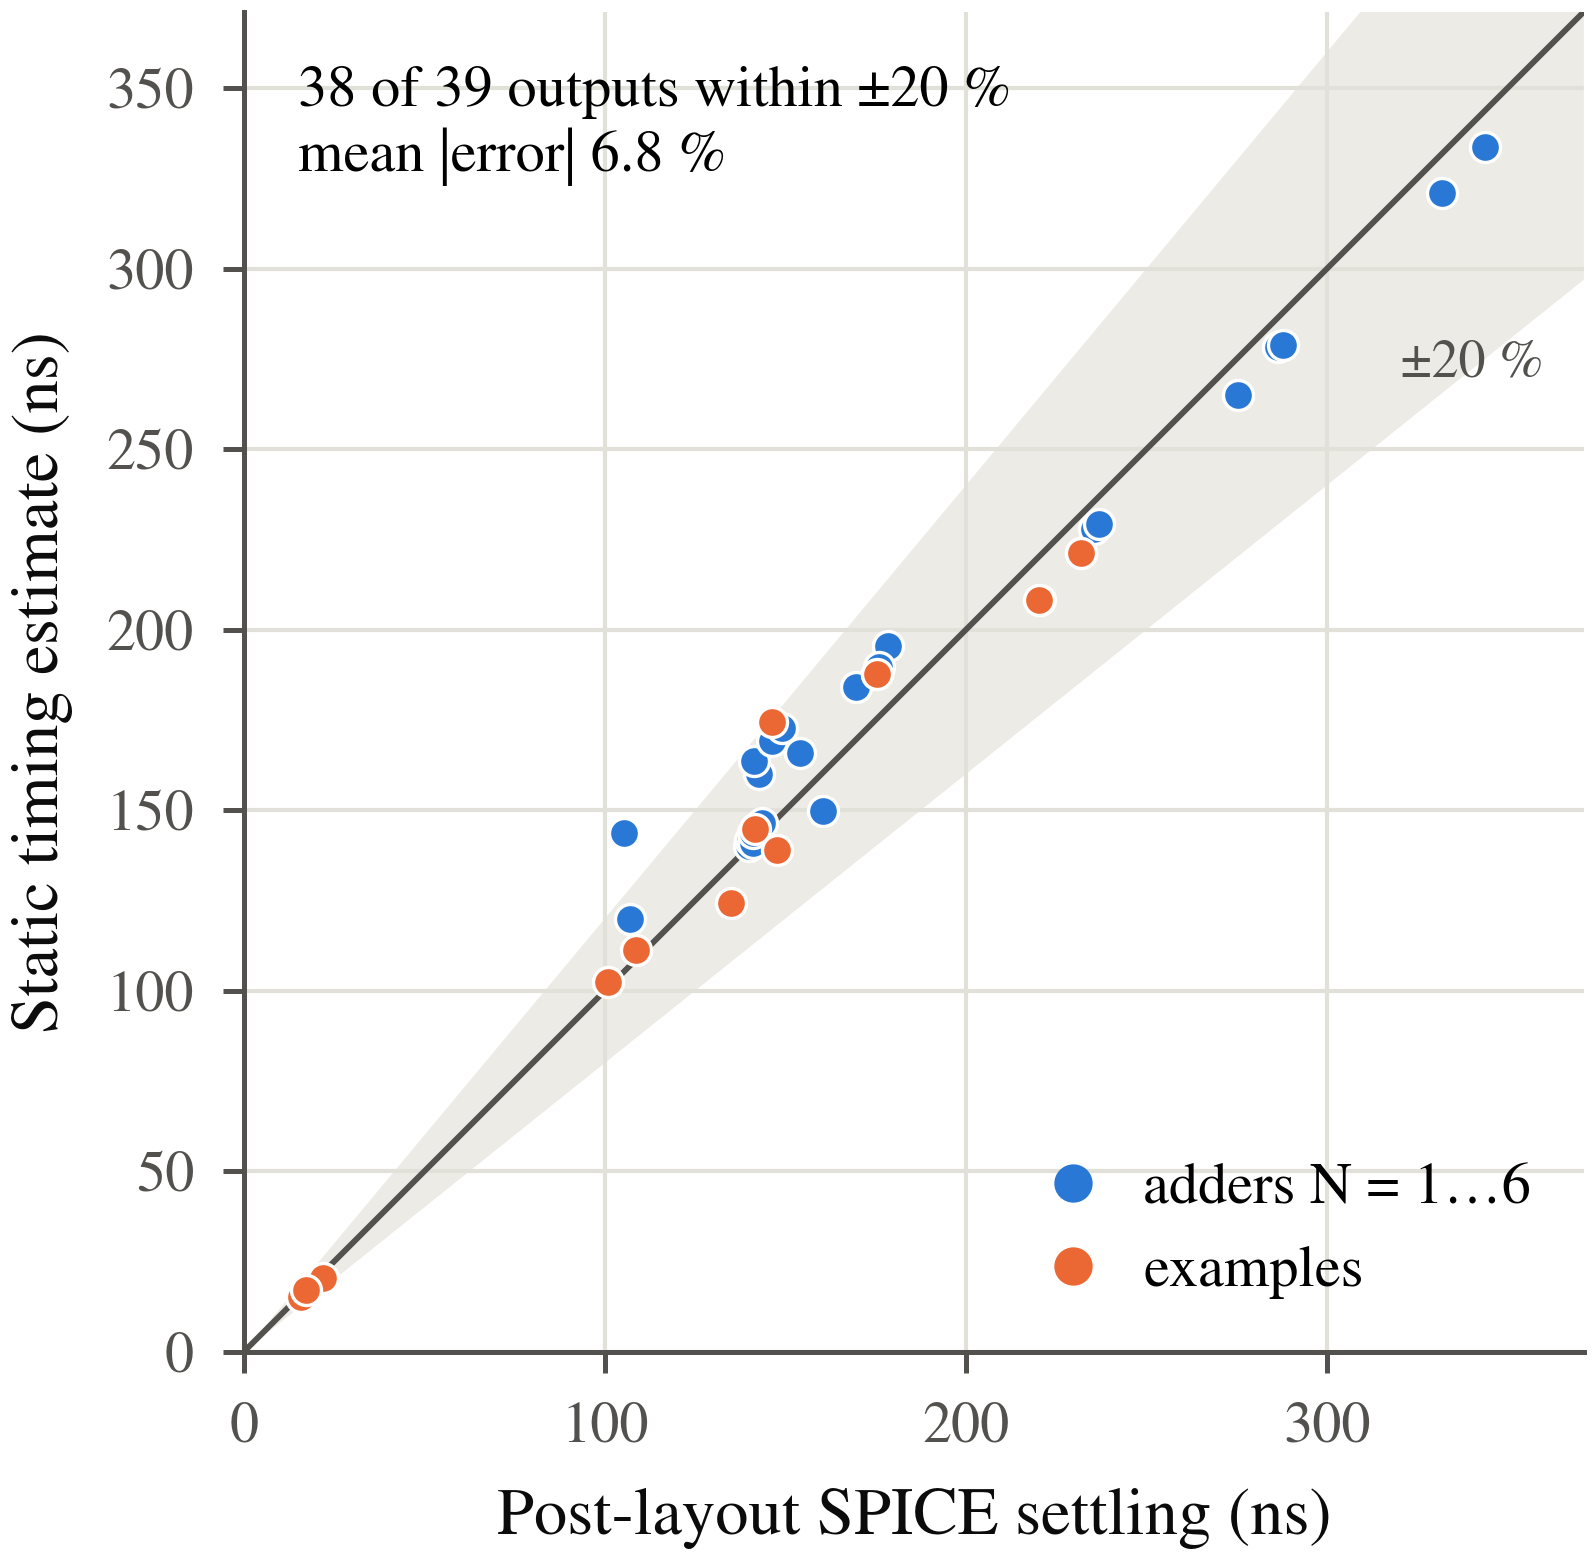

**Ternary static timing compared with extracted-circuit SPICE** Each point
compares an output's maximum over the same input-transition set, using
transition-class midpoint delays, propagated slew and one endpoint settling
tail; the line denotes equality and shading marks ±20%.
Across the example designs and adders of width
1–6, 38 of
39 output maxima fall within this band, with
6.782% mean absolute percentage error (routing realizations:
STA scaling: adder1, adder2, adder3, adder4, adder5, adder6; STA example: adder4, full_add, mac1, mul1).
The separate conservative envelope, not plotted here, averages
2.182× the measured maxima and is conservative on the saved
nominal cases, without constituting a certified analog bound.

> **What this shows.** In the recorded validation, 38 of
> 39 output maxima for matched input-transition sets lie
> within ±20% of SPICE, with 6.782% mean absolute
> percentage error. The exception is `scaling/adder2/cout`, overpredicted
> by 36.48%; partial-pulse amplitude and history are not
> represented by the event model.

The separate conservative bound averages 2.182× the measured
output maxima—about twice as loose—and covers the saved nominal cases,
without certifying untested waveforms or process/voltage/temperature corners.


## 8. Change the circuit and close the loop

Choose a sign detector, signed comparator, multiplier or min/max sorter.
Read its mathematical specification, then edit the HDL below and run the
design cell. The truth table first compares both source and mapped logic
with an independent integer reference. Placement, routing, drawing DRC, LVS
and extracted simulation then follow the same path as the opening adder.

*Set the circuit choice in the code cell, inspect its HDL, then change an
expression. The generated layout and waveform belong to that edited source.*

Keep the arithmetic reference while making an equivalent implementation.
If you change the intended function, edit that specification as well.
For a deliberate first experiment, try replacing a minimum with a maximum
in the sorter: the truth-table check identifies the disagreement before routing.



**Successful first edit:** the visible sorter below implements its minimum as `~((~a) | (~b))`. Run it to obtain a new mapped schematic and GDS while keeping the independent sorting reference.


In [ ]:
# Your circuit: edit this TritVerilog, then run the cells below.
# This first edit writes min(a, b) through De Morgan, as -max(-a, -b).
source = """
module minmax(input  trit a, b,
              output trit lo, hi);
  assign lo = ~((~a) | (~b));   // min(a, b)
  assign hi = a | b;            // max(a, b)
endmodule
"""


In [ ]:
from examples.curated import DESIGNS
from tritflow.synth import evaluate_netlist
CHOICE = os.environ.get("TRITFLOW_CIRCUIT", "minmax")   # or: sign | compare2 | mul2
example = DESIGNS[CHOICE]                                # its independent arithmetic reference
if CHOICE != "minmax":
    source = example.path.read_text()
print(example.description)


In [ ]:
custom_circuit = load_edited(example, source, BUILD/"your_circuit"/"source"/example.top)
custom = custom_circuit.synthesize()                                     # your HDL → cells
display(custom.schematic(net_names=True, title=f"{custom.top}: schematic of the edited HDL"))


In [ ]:
#@title Chapter 8 check: every input state against the independent arithmetic reference { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('custom_check', 'Chapter 8: Change the circuit and close the loop', requires=[]):
    truth = custom_circuit.truth_table()
    pins = custom_circuit.design.inputs
    planned = list(zip(*(truth[p] for p in pins)))
    oracle = example.oracle(pins)
    mapped_truth = evaluate_netlist(custom,{p:truth[p] for p in pins})
    for i, vector in enumerate(planned):
        expected = oracle(vector)
        source_actual = {p:int(truth[p][i]) for p in expected}
        mapped_actual = {p:int(mapped_truth[p][i]) for p in expected}
        if source_actual != expected or mapped_actual != expected:
            raise AssertionError(f"Independent reference disagreement at {dict(zip(pins,vector))}: "
                                 f"expected {expected}, HDL {source_actual}, cells {mapped_actual}. "
                                 "Check your edit; change the arithmetic reference only if you intend a different function.")
    details_html("Edited-circuit exhaustive truth table",truth_table_html(custom,max_rows=len(planned)))


In [ ]:
custom_out = BUILD/"your_circuit"/example.top
custom_lay = custom.place_and_route(output_dir=custom_out, seed=0, anneal_steps=600)   # → GDS
print("DRC clean:", custom_lay.drc()["clean"], "· LVS match:", custom_lay.lvs()["matched"])
display(Image(filename=str(render_gds(custom_lay.gds_path, custom_out/f"{custom.top}.layout.png",
                                      top=custom.top)), width=760))


In [ ]:
#@title Chapter 8: extracted SPICE of your layout and its waveform { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('custom', 'Chapter 8: Change the circuit and close the loop', requires=['custom_check']):
    custom_result = cache.run(f"your-{CHOICE}", {"source":source,"net":custom.to_json(),"vectors":planned,
                             "expected":[oracle(v) for v in planned],"load_f":10e-15,"hold_s":1e-6,
                             "step_s":2e-9,"rows":None,"anneal_steps":600,"seed":0,"initialize_internal":True},
        lambda: complete_design(custom,custom_out,planned,oracle,hold_s=1e-6,initialize_internal=True),
        artifacts=lambda r: experiment_artifacts(r,custom_out,example.top))
    assert_experiment(custom_result)
    assert {tuple(row["input_trits"]) for row in custom_result["post"]["measurements"]["rows"]} == set(planned)
    table([["Independent arithmetic input states",len(planned)], ["Physical results",custom_result["stats"]],
           ["DRC clean / LVS matched",[custom_result["drc"]["clean"],custom_result["lvs"]["matched"]]],
           ["Initial Newton guesses (V)",custom_result["initial_nodeset_v"]]],details="Selected circuit physical evidence and Newton guesses")

    show(waveform_figure(custom_result["post"],title=f"{CHOICE}: all input states, selected sequence"))
    custom_values = {"custom.name":custom.top,"custom.logic_states":len(planned),
        "custom.cells":custom.report()["total_cells"],"custom.die_um":dimensions(custom_result["stats"]["die_size_um"]),
        "custom.drc_items":custom_result["drc"]["violations"],"custom.lvs_status":"Match",
        "custom.analog_states":len(set(planned)),"custom.analog_status":"PASS"}
    custom_takeaway = (ROOT/"notebook/narrative/08_your_circuit.md").read_text().split("> **What this shows.**",1)[1]
    display(Markdown(render_narrative("> **What this shows.**"+custom_takeaway,{**narrative_values,**custom_values})))


A deliberately unsupported expression produces a located, readable error before synthesis:


In [ ]:
from tritflow.hdl import HDLError
broken = """
module broken(input trit a, b, output trit y);
  assign y = a + b;   // '+' on signals is not a gate
endmodule
"""
try:
    flow.loads(broken, "broken", filename="your_circuit.tv")
except HDLError as error:
    print(error)
    print("Repair: use gates for signal arithmetic; e.g. nany(a, b) gives the negative saturated sum.")
else:
    raise AssertionError("unsupported signal arithmetic must be rejected")


## 9. Next: compare the model with silicon

The reference-cell chip is expected in January 2027. Measurement
will connect the divider and timing predictions to real devices: first DC
output levels and static rail currents, then settling with known stimulus
edges and loads. The recorded supply voltages, temperature and probe loading
will define a matching SPICE experiment.

<div style="display:block;width:100%;min-width:0;max-width:100%;overflow-x:auto;contain:inline-size;box-sizing:border-box;">
<table width="100%" style="width:100%;min-width:0;max-width:100%;table-layout:fixed;border-collapse:collapse;">
<tr><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Measurement</th><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Record with the result</th><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Compare with SPICE</th></tr>
<tr><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Input DC sweep</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Supply voltages, temperature and rail currents</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Transfer curve and middle-level error</td></tr>
<tr><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Trit-to-trit step</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Input edge, skew and total output loading</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Final entry into the target voltage band</td></tr>
<tr><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Supply and temperature sweep</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Actual operating point at each measurement</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">Level and current sensitivity</td></tr>
</table>
</div>

The first comparison will sweep the input through the middle region and
measure the output and each rail current. Next, step between trit levels,
measure final entry into the same voltage bands, and repeat at several loads.
Record pad, package and instrument capacitance alongside the circuit load.
Supply and temperature sweeps can then show which discrepancies depend on
bias and which call for changes to the interconnect or device assumptions.


### From your HDL to a shuttle-ready top

A routed core still needs a frame, real terminals and mask preparation.
`PnrResult.to_chip()` places a compatible core inside a copy of the pinned
MPW TEG frame, preserves its seal ring and prohibited regions, and replaces
the copied pad bank with peripheral passive `OSS_PAD_TEG` pads. With the
canonical adder layout selected, the public calls are:

```python
chip = layout.result.to_chip()
checks = chip.signoff()
chip.gds_path
```

`to_chip()` builds and qualifies the full top; `ChipResult.signoff()` repeats
its checks or reuses unchanged verified reports. `layout.signoff()` alone
checks the core, so use the returned chip for full-top signoff. The output
includes the drawing GDS, circuit reference, pad map, prepared mask GDS and
native reports.


In [ ]:
chip = json.loads((ROOT/"notebook/assets/chip/adder4/signoff.json").read_text())   # recorded run, adder4 seed 7
display(Image(filename=str(ROOT/"notebook/assets/chip/adder4/tr_1um_adder4.png"), width=640))
table([["Check", "Result"]] + [[k, chip[k]] for k in
      ("drawing_drc", "drawing_lvs", "mask_drc", "mpw_precheck", "submission_ready", "reason")])
# Reproduce locally with KLayout and the OpenSUSI MPW template (see docs/status/PNR.md):
#   full = macro.to_chip(); full.signoff()


In [ ]:
#@title Chapter 9 checks: recorded signoff snapshot and pad map { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('shuttle', '9. Next: compare the model with silicon', requires=[]):
    assert chip["physical_checks_passed"] and chip["drawing_drc"]["clean"] and chip["mask_drc"]["clean"]
    assert chip["drawing_lvs"]["matched"] and chip["drawing_lvs"]["strict_ports"]
    assert hashlib.sha256((ROOT/"notebook/assets/chip/adder4/tr_1um_adder4.gds").read_bytes()).hexdigest() == chip["gds_sha256"]
    details_html("Pad map and remaining submission steps",
                 "<pre style='white-space:pre-wrap'>"+(ROOT/"notebook/assets/chip/adder4/README.md").read_text()+"</pre>")


> **What this shows.** The recorded framed adder based on paper/adder4 · seed 7 occupies
> 2500 × 2500 µm with 23 real pads: drawing DRC reports
> 0 items, strict drawing LVS is Match,
> mask DRC after mask-data preparation reports 0 items,
> and the MPW precheck is Pass.

Physical checks pass; `submission_ready` remains `false`.
Before submitting a real design:

1. Obtain the shuttle organizer's allocation approval for the full frame and
   its custom pad/probe map; this top does not fit the earlier shared slot.
2. Complete the bond/package diagram. Power every same-domain supply pad,
   supply VMID separately, and agree die attach and common substrate at VSS.
3. Obtain process and ESD approval for the -5/
   0/+5 V supplies. These passive pads have no
   ESD network; check package/probe loading, supply impedance and pad/bond
   current capability.
4. Complete the shuttle's metadata, license, schematic and circuit-reference
   package. Run the organizer's CI on the frozen revision and review the final
   masks and electrical results with the shuttle owner.

The inspected shuttle flow checks strict LVS on the drawing before mask-data
preparation; it defines no post-mask LVS check. TritFlow prepares the artifacts
and reports; it does not request an allocation or submit them.


## Appendix A. What the results establish

Logical equivalence, physical connectivity and analog settling answer different
questions. The tables in Appendix B identify the checks actually run and the
conditions of each result.

**Silicon.** The reference cells were taped out. Silicon has not yet been measured. Adapted standard-cell layouts and generated designs are simulation and layout results.

**Operating conditions.** Results use nominal models and the displayed supplies, temperature, input ramps and loads unless an explicitly labelled sweep says otherwise. No statistical mismatch or general PVT guarantee follows.

**Logic.** The HDL describes combinational ternary circuits. It has no sequential logic, `x`/`z` semantics or general signal arithmetic operators. Equivalence is exhaustive or sampled as stated for each design.

**Analog coverage.** Visiting all input states in one sequence does not test every directed transition or input skew. Larger circuits use labelled carry and arithmetic patterns. Static maxima cover only their listed DC states.

**Timing.** Settling means final band entry through the recorded interval, measured from input-ramp start. Sampling and interpolation limit resolution. An unsettled output has no finite reported delay. A longer interval may change a load pass/fail result.

**Static timing.** The accuracy comparison restricts STA to SPICE's tested transition sets and conditions; it does not establish accuracy over every transition. The event model propagates logical events and slew but does not resolve partial analog pulse amplitude/history. The separate conservative estimate covers the saved nominal observations; it is not a guaranteed bound for arbitrary waveforms or PVT.

**Wire model.** Device extraction uses the PDK LVS deck. Added wire capacitance is a per-net lumped estimate from connected metal area and perimeter with assumed coefficients, not calibrated parasitic extraction. Signal-wire resistance, coupling, distributed poly RC and package effects are absent from the main comparison.

**Device comparison.** Equal intrinsic devices establish circuit identity. The metal-capacitance comparison adds geometry-dependent loading; neither comparison establishes full interconnect-RC or silicon equivalence.

**Hand estimates.** The divider uses approximate on-resistances and a simplified resistor model. The ripple estimate repeats a standalone carry stage; the DC cell sum uses the all-zero bias. These are explanatory predictions, not bounds on arbitrary inputs or paths.

**Poly resistance.** Optional poly-resistance studies are sensitivity calculations with an assumed gate-poly sheet resistance. Device-resistor and MOS diffusion parameters are not substitutes for a calibrated gate-poly model.

**Power delivery.** Divider cells consume static power. The rail-resistance network uses characterized current envelopes and assumed metal/via resistance; it is separate from the ideal-supply SPICE waveforms. Width-scaled published DC limits and reserved margin do not establish lifetime, transient, pad, bond or current-crowding qualification.

**Manufacturing.** Core and framed-top checks are identified separately. The optional TEG wrapper has drawing DRC, strict drawing LVS, mask preparation, mask DRC and the inspected MPW precheck; no post-mask LVS stage is defined. Its passive pads have no ESD network. Allocation/custom pad-map approval, all supply bonds, substrate/die-attach agreement, package/load/current checks, process/ESD approval and final organizer CI remain necessary for submission.


The physical-library and experiment files in Appendix B keep the assumptions
and the tested input plans available for reuse.


## Appendix B. Verification evidence and how to rerun

Each result below links its HDL, library, PDK and native reports. A recorded
result retains the tools and conditions of the run that created it. Reading a
saved report does not execute a new physical or electrical check.

Use the routing realization below to distinguish paper figures from the
four-design results; a circuit name alone does not identify its layout.

<div style="display:block;width:100%;min-width:0;max-width:100%;overflow-x:auto;contain:inline-size;box-sizing:border-box;">
<table width="100%" style="width:100%;min-width:0;max-width:100%;table-layout:fixed;border-collapse:collapse;">
<tr><th width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Figure or result set</th><th width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">Routing realization</th></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Paper adder overview and placement</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">paper/adder4 · seed 7</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Paper full-adder waveform and load sweep</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">paper/full_add · seed 19</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Paper width sweep</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">width-sweep · seed 7</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Four-design archive: adder4</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">four-design/adder4 · seed 0</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Four-design archive: full_add</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">four-design/full_add · seed 0</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Four-design archive: mac1</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">four-design/mac1 · seed 0</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">Four-design archive: mul1</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">four-design/mul1 · seed 0</td></tr>
</table>
</div>

The detailed physical and timing tables repeat that identifier in a
**Routing realization** column on every design/output row. The paper and
archived full adders use different routes, so their sum-settling values are
separate measurements even at the same external load and input interval.

For each analog experiment, the expanded table gives the actual input order,
unique states visited, possible states, interval, edge time, maximum timestep,
temperature, external load, initialized segment and pass criteria. Per-output
band errors and settling times accompany the waveforms. Initialization is
excluded from transition maxima. Soft Newton starting guesses, when used,
are listed with the circuit; they do not constrain the transient.

**Run the notebook.** Open the Colab badge and select **Runtime → Run all**.
The setup cell prints the resolved source revision and installed tools.
The default session runs the opening adder and selected editable circuit;
larger sizing, width and load sweeps can read their recorded data. The closing
table labels fresh calculations, local reuse and recorded experiments, with
wall time for each stage. The closing cell prints the measured runtime for this session, including setup. The Colab record above names its
tested source, completion and timing scope, including any setup retry; a
historical successful run does not verify a later revision.

The STA table compares `tested_predicted_s` with `simulated_s` for each
design/output and identifies its matched input plan, load and routing
realization. Keep the separate `predicted_s` conservative estimate and its
coverage in separate columns. Show the out-of-target endpoint as well as the
points within the accuracy band; a mostly accurate comparison is not an
all-output accuracy pass. The framed-top table identifies the source core,
frame and pad map and gives drawing DRC, strict drawing LVS, mask DRC and
MPW precheck separately, alongside `submission_ready` and the remaining
approval steps. No post-mask LVS result is implied.

<details>
<summary>Repeat the calculations</summary>

Set `TRITFLOW_FORCE_RUN=1` before running to recompute expensive notebook stages,
including the shared-design examples. This bypasses both the local result
cache and the recorded shared-design archive. The variable does not regenerate
the separate cell-characterization, sizing, width or load publications.
`TRITFLOW_EXTENDED=1` enables the additional notebook experiments.
The build directory is selected by `TRITFLOW_NOTEBOOK_BUILD`.

From a full checkout with the pinned PDK and tools installed, these commands
regenerate the larger simulation experiments and check their results:

```sh
python3 -m tritflow.sim.sizing
python3 examples/postlayout_all.py
python3 examples/adder_scaling.py --jobs 1
python3 -m tritflow.sim.publication
python3 -m pytest tests/sim tests/extract -q
```

With the same native SPICE outputs available, `python3 -m tritflow.sta.validate`
recomputes the timing comparisons without rerunning SPICE. The chip API in
chapter 9 retains its reports under the chip's `signoff/` directory;
`chip.signoff(force=True)` requires fresh full-top checks. Default repeated
calls validate the saved artifacts before reuse.

`tritflow.sim.load_sweep.sweep_output_load(directory, destination=...)` repeats
the full-adder load experiment against the generated physical design.
`tritflow.sim.scaling.run_scaling(...)` selects widths and a destination for a
new scaling experiment. Existing inputs and native outputs are checked before
reuse; remove the corresponding experiment output or choose a new destination
to require fresh computation. Failed or missing measurements stay visible.

Run the HDL, synthesis and physical regressions separately when changing those
parts of the flow. Native DRC/LVS reports, SPICE decks, simulator logs and
waveforms are retained beside each generated design.

</details>

<details>
<summary>Sources and licenses</summary>

[TritFlow](https://github.com/PenguinEino/tritflow), the
[author's reference ternary circuits](https://github.com/PenguinEino/opensusi-tr10-balanced-ternary-logic)
and [OpenSUSI TR-1um](https://github.com/OpenSUSI/TR-1um) provide the design
sources. KLayout packages come from the
[official distribution](https://www.klayout.de/build.html).
The submission includes its Apache-2.0 license and NOTICE; the derived
historical schematic illustrations are released by their author under the
same license. The PDK retains its own license and attribution.

</details>


Free Colab verification at [7b62e63](https://github.com/PenguinEino/tritflow/commit/7b62e63f9f75acfa5f935c8da58a77a9db42e0cc): all 35 code cells completed in 384.4 s including setup.

If Run all stops after setup, choose Run all again.


<details><summary>Setup, recovery and source selection</summary>

Colab shallow-clones `colab-v0` into `/content/tritflow`; `TRITFLOW_REF` selects another release.
Use the source revision matching this notebook. Setup preserves Colab's NumPy/SciPy/Matplotlib/Plotly,
checks minimum versions, and prints KLayout/ngspice versions. If mixed versions are detected,
restart once and rerun setup/imports. After a failed chapter, rerun its named prerequisite.
Missing or changed scientific inputs stop execution; changed illustrations only warn.
The closing table distinguishes calculations from recorded experiments.

</details>


In [ ]:
#@title Appendix B: cell characterization and fanout evidence { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('characterization', 'Appendix B: Verification evidence and how to rerun', requires=[]):
    characters = {cell: json.loads((CELLS_DIR/f"out/{cell}/{cell}.char.json").read_text())
                  for cell in ["INV","NAND","NOR","NANY","BUF"]}
    rows = [["Cell", "Max DC error (mV)", "Max static rail |I| (µA)", "Input C (fF)", "Suggested fanout"]]
    for cell, char in characters.items():
        assert hashlib.sha256((CELLS_DIR/f"out/{cell}/{cell}.ext.spice").read_bytes()).hexdigest() == char["source_sha256"]
        assert all(hashlib.sha256((PDK_ROOT/"libs.tech/spice/models"/name).read_bytes()).hexdigest() == value
                   for name,value in char["model_sha256"].items()), cell
        assert char["passed"] and all(row["passed"] for row in char["dc"])
        assert len({tuple(row["input_trits"]) for row in char["dc"]}) == 3**len(char["inputs"])
        assert all(result["passed"] for result in char["transient"])
        rows.append([cell, 1e3*max(abs(v) for row in char["dc"] for v in row["error_v"].values()),
                     max(abs(i) for row in char["dc"] for i in row["rail_current_a"].values())*1e6,
                     char["input_capacitance"]["max_f"]*1e15, char["fanout"]["suggested_max"]])
    characterization_rows = rows
    evidence("Full-precision DC checkpoints", {cell:char["dc"] for cell,char in characters.items()})
    table([["Cell", "Recorded conditions", "Tested loads (fF)", "Fanout evidence"]]+
          [[cell, char["conditions"], [r["load_f"]*1e15 for r in char["transient"]], char["fanout"]]
           for cell,char in characters.items()], details="Characterization conditions and complete fanout evidence")
    fanout_rows = [["Cell", "Measured receiver counts", "Chain depth", "Worst chain (ns)",
                    "Driver at largest tested fanout (ns)", "Max level error (mV)"]]
    for cell, char in characters.items():
        cascade = char["cascade"]
        assert cascade["source_sha256"] == char["source_sha256"]
        assert cascade["passed"] and cascade["chains_passed"] and all(c["passed"] for c in cascade["cases"])
        largest = max(cascade["fanouts_tested"])
        chain_times = [t for c in cascade["cases"] if c["mode"] == "chain"
                       for t in c["max_settling_s"].values() if t is not None]
        loaded_times = [c["max_settling_s"]["y0"] for c in cascade["cases"]
                        if c["mode"] == "fanout" and c["fanout"] == largest]
        fanout_rows.append([cell, cascade["fanouts_tested"], cascade["chain_depth"],
                           max(chain_times)*1e9, max(loaded_times)*1e9,
                           max(c["max_error_v"] for c in cascade["cases"])*1e3])


In [ ]:
#@title Appendix B: four-design physical and timing campaign { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('four', 'Appendix B: Verification evidence and how to rerun', requires=[]):
    from tritflow.sim.postlayout import representative_vectors, arithmetic_oracle
    FOUR_DESIGN_LOAD_F, FOUR_DESIGN_HOLD_S, FOUR_DESIGN_STEP_S = 10e-15, 500e-9, 2e-9
    four_results = {}
    physical_rows = [["Design", "Routing realization", "Die (µm)", "Aspect", "Utilization", "DRC / LVS", "Input states visited / possible",
                      "Post max error (mV)", "Rail deviation / zero shift (mV)"]]
    timing_rows = [["Design", "Routing realization", "Output", "Device-only max (ns)", "+ wire-C max (ns)", "Largest same-transition change (ns)"]]
    four_run_labels = {}
    for name, source_name, params in [("adder4","adder",{"N":4}), ("full_add","full_add",{}),
                                      ("mac1","mac1",{}), ("mul1","mul1",{})]:
        mapped = flow.load(ROOT/f"examples/{source_name}.tv", source_name, params).synthesize(name=name)
        pins = [p.name for p in mapped.ports if p.dir == "input"]
        planned, labels = representative_vectors(name, pins)
        oracle = arithmetic_oracle(name, pins)
        directory = BUILD/"four_designs"/name
        options = {"net":mapped.to_json(),"vectors":planned,"labels":labels,
                   "expected":[oracle(v) for v in planned],"load_f":FOUR_DESIGN_LOAD_F,
                   "hold_s":FOUR_DESIGN_HOLD_S,"step_s":FOUR_DESIGN_STEP_S,
                   "rows":None,"anneal_steps":600,"seed":0,"initialize_internal":True}
        lookup_started = time.monotonic()
        result = None if cache.force else recorded_campaign.get(name,options)
        if result is not None:
            cache.events.append((f"four-{name}","recorded"))
            cache.timings.append({"stage":f"four-{name}","state":"recorded",
                                  "elapsed_s":time.monotonic()-lookup_started})
            print(f"Recorded {name}: retained native checks; see Appendix B")
        else:
            result = cache.run(f"four-{name}",options,
                lambda: complete_design(mapped,directory,planned,oracle,load_f=FOUR_DESIGN_LOAD_F,
                           hold_s=FOUR_DESIGN_HOLD_S,step_s=FOUR_DESIGN_STEP_S,initialize_internal=True,dataset='four-design'),
                artifacts=lambda r: experiment_artifacts(r,directory,name))
        assert_experiment(result)
        state = 'recorded' if cache.events[-1][1] == 'recorded' else ('fresh' if cache.events[-1][1] == 'run' else 'local reuse')
        if state == 'recorded':
            assert result['routing'] == archive_routing(ROOT/'notebook/assets/four_designs.zip')[name]
        run_label = routing_label(result['routing'],state=state,digest=True)
        four_run_labels[name] = run_label
        assert result["post"]["stimulus"]["vectors"] == list(map(tuple,planned))
        stats, ir = result["stats"], result["ir"]
        rail = max(abs(v) for c in ir["cells"].values() for v in c["rail_deviation_v"].values())
        zero = max(abs(c["zero_level_shift_v"]) for c in ir["cells"].values() if c["zero_level_shift_v"] is not None)
        physical_rows.append([name,run_label,stats["die_size_um"],max(stats["die_size_um"])/min(stats["die_size_um"]),
                              stats["utilization"],[result["drc"]["clean"],result["lvs"]["matched"]],
                              f"{len(set(planned))} / {3**len(pins)}",result["post"]["measurements"]["max_error_v"]*1e3,
                              [rail*1e3,zero*1e3]])
        before, after = [result[mode]["measurements"] for mode in ("pre","post")]
        for pin in after["max_settling_s"]:
            changes = [b["outputs"][pin]["settling_s"]-a["outputs"][pin]["settling_s"]
                       for a,b in zip(before["rows"][1:],after["rows"][1:],strict=True)]
            timing_rows.append([name,run_label,pin,before["max_settling_s"][pin]*1e9,after["max_settling_s"][pin]*1e9,
                                max(changes)*1e9])
        four_results[name] = result


    if recorded_campaign.manifest:
        evidence("Recorded four-design producer tools (not local requalification)",
                 recorded_campaign.manifest["tools"])
    table([["Shared load (fF)",FOUR_DESIGN_LOAD_F*1e15], ["Hold / max step (ns)",
           [FOUR_DESIGN_HOLD_S*1e9,FOUR_DESIGN_STEP_S*1e9]],
           ["Input plan labels", {name:representative_vectors(name,
              r["post"]["stimulus"]["inputs"])[1] for name,r in four_results.items()}]],details="Four-design stimulus conditions and labels")


In [ ]:
#@title Appendix B: evidence tables, provenance and run time { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('final', 'Appendix B: Verification evidence and how to rerun', requires=['opening_inputs', 'opening', 'gates', 'sizing', 'cells', 'arithmetic', 'synthesis', 'pnr', 'pre', 'published', 'sta', 'custom_check', 'custom', 'shuttle', 'characterization', 'four']):
    table(characterization_rows,details="Cell DC / capacitance / fanout summary")
    table(fanout_rows,details="Transistor-level cascade and fanout tests")
    table(cell_dimension_rows,details="All standard-cell dimensions and pin-access tracks")
    table(cell_qualification_rows,details="Cell drawing-DRC and LVS qualification")
    table(physical_rows,details="Four-design physical and arithmetic checks (retained or fresh as below)")
    table(timing_rows,details="Four-design identical-device timing comparison")
    evidence("Cell ordered-pair/orientation abutments",report["abutment"])
    for name,grid in sizing_grids.items():
        evidence(name+" sizing status including unavailable points",[
            {"index":i,"dimensions":r["dimensions"],"passed":r["passed"],"error":r["error"]}
            for i,r in enumerate(grid["rows"]) if not r["passed"]])
    evidence("Live adder acceptance, sequence and initialized Newton guesses",{
        "logic":net.report()["equivalence"],"labels":vector_labels,"vectors":vectors,
        "measurements":demo["measurements"],"nodeset":demo["initial_nodeset_v"],
        "conditions":{"load_f":LOAD_F,"hold_s":HOLD_S,"edge_s":EDGE_S,"step_s":STEP_S,"temperature_c":TEMP_C}})
    evidence("Native paper-figure inputs and committed image/data hashes",paper)
    table([["Routing realization", "PNR SHA-256", "GDS SHA-256"]]+
          [[routing_label(r),r['pnr_sha256'],r['gds_sha256']]
           for r in (paper['paper_pnr']['routing'],paper['paper_post']['routing'])]+
          [[four_run_labels[name],r['routing']['pnr_sha256'],r['routing']['gds_sha256']]
           for name,r in four_results.items()],details="Native identities for each paper and four-design routing realization")
    assert (runtime_fingerprint(ROOT,PDK_ROOT,names=native_sources) == cache.fingerprint and
            source_manifest(ROOT,PDK_ROOT,names=native_sources) == native_sources), "consumed sources changed during Run all; rerun after publication settles"
    load_paper(ROOT)  # measurements remain strict; illustration changes only warn
    table([["Stage", "Fresh / local cache / recorded", "Wall time this run (s)"]]+[
        [r["stage"],r["state"],round(r["elapsed_s"],3)] for r in sorted(cache.timings,key=lambda r:r["elapsed_s"],reverse=True)])
    table([["Design", "Routing realization", "Measured producer phase", "Wall time (s)", "Process + child CPU time (s)"]]+[
        [name,four_run_labels[name],stage,round(seconds,3),round(result["cpu_times_s"][stage],3)] for name,result in four_results.items()
        for stage,seconds in result["timings_s"].items()],details="Physical and pre/post-SPICE runtime breakdown (producer evidence)")
    print("Cache stages:")
    for name,state in cache.events:
        print(f"  {name}: {state}")
    print(f"Run time including setup: {time.monotonic()-started:.1f} s")
    print("Artifacts:", BUILD)


## Appendix C. Use and extend TritFlow

Start in Colab for the installed EDA environment, or keep an editable source
checkout locally. The repository contains the example HDL, generated cell
views and notebook assets needed by the flow; installing the Python package
alone does not supply those files.

### Install from GitHub

From an empty working directory, install the selected source revision:

```sh
python3 -m pip install --src ./src -e "git+https://github.com/PenguinEino/tritflow.git@colab-v0#egg=tritflow"
cd src/tritflow
```

The full flow also needs native KLayout with its Ruby DRC/LVS engine, ngspice
and the pinned OpenSUSI PDK. On the supported Ubuntu amd64 releases, use the
repository's setup script:

```sh
bash notebook/colab_setup.sh --source "$PWD"
```

For an existing tool installation, set `TR1UM_PDK` to the qualified PDK tree
and, if needed, `KLAYOUT_BINARY` to the native executable. The exact source,
PDK and tool pins live in `notebook/setup_pins.json`; setup details and supported
platforms are in `notebook/README.md`.

### The seven-line API

Run from the source root after setup:

```python
from tritflow import flow
design = flow.load("examples/adder.tv", "adder", {"N": 2})
net = design.synthesize(name="adder2")
layout = net.place_and_route(output_dir="build/adder2")
assert layout.drc()["clean"] and layout.lvs()["matched"]
vectors = [tuple(0 for p in net.ports if p.dir == "input")]
post = layout.extract().simulate(vectors, load=100e-15)
```

This is a zero-input smoke simulation. `load` is in farads; each vector follows
the bit-blasted input-port order in `net.ports`. The default expected outputs
come from the mapped logic. For an arithmetic result, supply an independent
integer oracle with `expected=` and a transition plan that exercises the
intended paths, as the notebook does. Inspect `post["measurements"]` for level
and settling results; completing a simulation alone does not assert a pass.
`layout.extract(wire_c=False)` selects extracted devices alone; the default
adds the geometry-based wire-capacitance estimate.

Inspect the circuit before routing with `net.schematic(expand="*").show()`;
use `.save("build/adder2.svg")` to retain the same schematic. Chapter 7 shows
`tritflow.sta.analyze`, and chapter 9 shows the separate full-chip wrapper.
Use `flow.loads(source, top=..., params=...)` for HDL supplied as a string.

### Command-line entry points

These commands run from the same source root. They write under `build/` and
retain the native reports beside their outputs.

```sh
python3 -m tritflow.synth examples/adder.tv --top adder -P N=2 --name adder2 -o build/adder2
python3 -m tritflow.pnr build/adder2/adder2.json -o build/adder2 --seed 7
```

The synthesis command writes gate JSON, mapped TritVerilog, SPICE and its
equivalence report. P&R writes GDS and the placement/routing record and runs
physical checks. Use the Python API above for extracted simulation and chip
wrapping; there is no generic `tritflow` executable or `tritflow.sta` module CLI.

For library development, build and check a private output directory:

```sh
python3 -m tritflow.cells build --out build/cell_trial
python3 -m tritflow.cells verify --out build/cell_trial
python3 -m tritflow.sim.characterize INV --spice build/cell_trial/INV/INV.ext.spice --destination build/INV.char.json
```

The private `build` command generates views; `verify` performs the physical
and DC checks. `python3 -m tritflow.sta.characterize --help` describes midpoint
timing characterization, and `python3 -m tritflow.sta.validate` repeats the
STA-to-SPICE comparison against existing native simulation evidence. Appendix B
lists the separate larger electrical experiments and their rerun commands.

### Add a cell

Define the circuit, ports and truth function in
`tritflow/cells/circuits.py`. Add its geometry in `tritflow/cells/compact.py`
(`WIDTHS` and drawing dispatch), using the PDK primitives in
`tritflow/cells/primitives.py`; `tritflow/cells/layout.py:build_cell` emits
the GDS, source SPICE, abstract and truth table. Preserve the common row height,
grid, rail order and legal pin access, and describe every internal routing
obstruction in the abstract.

A new logical cell also needs its pin order and evaluation in
`tritflow/synth/simulate.py` (`CELL_INPUTS`, `evaluate_netlist`), its SPICE pin
order in `tritflow/sim/spice.py:CELL_PINS`, its characterization reference in
`tritflow/sim/characterize.py:logic_value`, and a mapping rule in
`tritflow/synth/mapping.py:Mapper`. If exposed as an HDL primitive, extend
`tritflow/hdl/parser.py:GRAMMAR` and `tritflow/hdl/elaborate.py:Elaborator.items`.
Add its function to `tritflow/sta/logic.py` and characterize its transition
classes before using STA; add a schematic symbol in `tritflow/schematic/render.py`
when the cell needs a new drawing.

Check the truth function independently, then drawing DRC, strict LVS, DC
levels, loaded transients and row abutment. Use the private library for trial
routing and extracted simulation before replacing the distributed cell views.
Existing-device assumptions in the extraction decks need review if a new cell
introduces a different device type.

### Add an operator

First consider a reusable HDL module composed of the existing trit operations.
For new syntax, extend `tritflow/hdl/parser.py:GRAMMAR` and
`tritflow/hdl/elaborate.py:Elaborator.expression`, define evaluation in
`tritflow/hdl/ir.py:Design.evaluate`, and add explicit constant-folding and
rewrite behavior in `tritflow/synth/optimize.py`. Map the operator to existing
cells in `tritflow/synth/mapping.py:Mapper.map`; a new physical cell requires
the additional steps above.

Exhaust all trit combinations for the small operator and check the source,
optimized graph and mapped cells against an independent definition. Add
diagnostic tests for invalid uses and test each rewrite over the ternary
domain before enabling it. Boolean identities do not automatically hold for
the middle level.

Run the affected regressions, then the relevant native checks:

```sh
python3 -m pytest tests/hdl tests/synth -q
python3 -m pytest tests/cells tests/pnr tests/sim tests/extract -q
python3 -m pytest tests/sta tests/schematic -q
```

Keep the input plan, tool/PDK revisions and failed as well as passing results
with a new example so another designer can repeat the comparison.
